In [1]:
import numpy as np
import xarray as xr
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from scipy.stats import linregress
from matplotlib.font_manager import FontProperties

In [2]:


def schmidt_number(T):
    """Calculate Schmidt number for CO2 in seawater (Wanninkhof 2014)."""
    return 2116.8 - 136.25 * T + 4.7353 * T**2 - 0.092307 * T**3 + 0.0007555 * T**4

def solubility_weiss(T, S):
    """
    CO2 solubility in mol/m³/µatm from Weiss (1974).
    T: temperature in degC
    S: salinity in PSU
    """
    TK = T + 273.15  # Kelvin
    lnK0 = (-58.0931 + 90.5069 * (100 / TK) +
            22.2940 * np.log(TK / 100) +
            S * (0.027766 - 0.025888 * (TK / 100) + 0.0050578 * (TK / 100) ** 2))
    K0 = np.exp(lnK0)  # mol/L/atm
    return K0 * 1000  # convert to mol/m³/atm

def air_sea_CO2_flux(T, S, U, pCO2_sea, pCO2_air):
    """
    Calculate air-sea CO₂ flux (mol/m²/s).
    
    Parameters:
    T: Sea surface temperature (°C)
    S: Sea surface salinity (psu)
    U: Wind speed at 10 m (m/s)
    pCO2_sea: Sea surface pCO₂ (µatm)
    pCO2_air: Atmospheric pCO₂ (µatm)
    
    Returns:
    CO₂ flux in mol/m²/yr
    """
    # Schmidt number
    Sc = schmidt_number(T)

    # Gas transfer velocity k (m/s) using Wanninkhof 2014 (with unit correction)
    k_660 = 0.251 * U**2  # cm/hr
    k = k_660 * (Sc / 660) ** -0.5  # cm/hr
    k_m_s = k / 100 / 3600  # convert to m/s

    # Solubility α (mol/m³/µatm)
    alpha = solubility_weiss(T, S) / 1e6  # mol/m³/µatm

    # Flux (mol/m²/s)
    flux = k_m_s * alpha * (pCO2_sea - pCO2_air)  # mol/m²/s

    # Convert to mol/m²/yr
    flux_yr = flux * 60 * 60 * 24 * 365  # seconds → year

    return flux_yr


In [3]:
ds = xr.open_dataset("pCO2-Corrected_INCOIS-BIO-ROMS.nc")
pco2 = ds["pCO2_Clim"]  # shape: (TIME, LAT, LON)
pco2_dev = pco2 + ds["Deviant_uncertainty"]
temp = ds["SST"]
sal = ds["SSS"]

In [4]:
pco2_atm = xr.open_dataset('pCO2_atm_gridded_1deg.nc').pCO2_atm
pco2_atm = pco2_atm.rename({"time":"TIME","lat":"LAT","lon":"LON"})
pco2_atm['TIME'] = ds.TIME
pco2_atm = pco2_atm.interp(TIME=ds.TIME, LAT=ds.LAT, LON=ds.LON, method="nearest")

In [5]:
ws = xr.open_dataset('wind_speed_JRA.nc').WS
ws['TIME'] = ds.TIME
ws = ws.interp(TIME=ds.TIME, LAT=ds.LAT, LON=ds.LON, method="nearest")

In [6]:
mask_AS = xr.where(np.isnan(pco2.sel(LON=slice(30,78),LAT=slice(0,30)).mean(dim='TIME')), 0,1)
mask_EAS = xr.where(np.isnan(pco2.sel(LON=slice(30,65),LAT=slice(0,30)).mean(dim='TIME')), 0,1)
mask_WAS = xr.where(np.isnan(pco2.sel(LON=slice(65,78),LAT=slice(0,30)).mean(dim='TIME')), 0,1)
mask_BoB = xr.where(np.isnan(pco2.sel(LON=slice(78,110),LAT=slice(0,30)).mean(dim='TIME')), 0,1)
mask_SBoB = xr.where(np.isnan(pco2.sel(LON=slice(78,110),LAT=slice(0,15)).mean(dim='TIME')), 0,1)
mask_NBoB = xr.where(np.isnan(pco2.sel(LON=slice(78,110),LAT=slice(15,30)).mean(dim='TIME')), 0,1)
mask_EIO = xr.where(np.isnan(pco2.sel(LON=slice(30,120),LAT=slice(-18,0)).mean(dim='TIME')), 0,1)
mask_SIO = xr.where(np.isnan(pco2.sel(LON=slice(30,120),LAT=slice(-30,-18)).mean(dim='TIME')), 0,1)
mask_ESIO = xr.where(np.isnan(pco2.sel(LON=slice(75,120),LAT=slice(-30,-18)).mean(dim='TIME')), 0,1)
mask_WSIO = xr.where(np.isnan(pco2.sel(LON=slice(30,75),LAT=slice(-30,-18)).mean(dim='TIME')), 0,1)

In [7]:
area_AS = mask_AS.sum()*64*1e6
area_EAS = mask_EAS.sum()*64*1e6
area_WAS = mask_WAS.sum()*64*1e6
area_BoB = mask_BoB.sum()*64*1e6
area_SBoB = mask_SBoB.sum()*64*1e6
area_NBoB = mask_NBoB.sum()*64*1e6
area_EIO = mask_EIO.sum()*64*1e6
area_SIO = mask_SIO.sum()*64*1e6
area_ESIO = mask_ESIO.sum()*64*1e6
area_WSIO = mask_WSIO.sum()*64*1e6

In [8]:
mask_pco2 = pco2.mean(dim=['TIME']).notnull()

In [9]:
ws = ws.where(mask_pco2)
pco2_atm = pco2_atm.where(mask_pco2)

In [10]:
# flux = xr.open_dataset("Flux.nc").flux
# flux_un = xr.open_dataset('Flux_un.nc').flux_un

# 8089

In [11]:
pco2_8089 = pco2.sel(TIME=slice('1980','1989')).groupby('TIME.month').mean() 
pco2_atm_8089 = pco2_atm.sel(TIME=slice('1980','1989')).groupby('TIME.month').mean() 
temp_8089 = temp.sel(TIME=slice('1980','1989')).groupby('TIME.month').mean() 
sal_8089 = sal.sel(TIME=slice('1980','1989')).groupby('TIME.month').mean() 
ws_8089 = ws.sel(TIME=slice('1980','1989')).groupby('TIME.month').mean() 

## AS

In [12]:
pco2_AS_8089 = pco2_8089.sel(LON=slice(30,78),LAT=slice(0,15)).mean(dim=['LAT','LON'])
pco2_atm_AS_8089 = pco2_atm_8089.sel(LON=slice(30,78),LAT=slice(0,15)).mean(dim=['LAT','LON'])
temp_AS_8089 = temp_8089.sel(LON=slice(30,78),LAT=slice(0,15)).mean(dim=['LAT','LON'])
sal_AS_8089 = sal_8089.sel(LON=slice(30,78),LAT=slice(0,15)).mean(dim=['LAT','LON'])
ws_AS_8089 = ws_8089.sel(LON=slice(30,78),LAT=slice(0,15)).mean(dim=['LAT','LON'])

flux_AS_8089 = air_sea_CO2_flux(temp_AS_8089, sal_AS_8089, ws_AS_8089, pco2_AS_8089, pco2_atm_AS_8089)*area_AS*(12.0 / 1e15)
sea_flux_AS_8089 = flux_AS_8089 - flux_AS_8089.mean()

temp_AS_8089_dev = temp_AS_8089 + 0.0001*temp_AS_8089.mean()
flux_T_AS_8089 = air_sea_CO2_flux(temp_AS_8089_dev, sal_AS_8089, ws_AS_8089, pco2_AS_8089, pco2_atm_AS_8089)*area_AS*(12.0 / 1e15)
der_T_AS_8089 = ((flux_T_AS_8089-flux_AS_8089)/(0.0001*temp_AS_8089.mean()))
anm_T_AS_8089 = (temp_AS_8089 - temp_AS_8089.mean())
T_AS_8089 = der_T_AS_8089*anm_T_AS_8089
# T_AS_8089 = ((flux_T_AS_8089-flux_AS_8089)/(0.0001*temp_AS_8089))*(temp_AS_8089 - temp_AS_8089.mean())

sal_AS_8089_dev = sal_AS_8089 + 0.0001*sal_AS_8089.mean()
flux_S_AS_8089 = air_sea_CO2_flux(temp_AS_8089, sal_AS_8089_dev, ws_AS_8089, pco2_AS_8089, pco2_atm_AS_8089)*area_AS*(12.0 / 1e15)
der_S_AS_8089 = ((flux_S_AS_8089-flux_AS_8089)/(0.0001*sal_AS_8089.mean()))
anm_S_AS_8089 = (sal_AS_8089 - sal_AS_8089.mean())
S_AS_8089 = der_S_AS_8089*anm_S_AS_8089
# S_AS_8089 = ((flux_S_AS_8089-flux_AS_8089)/(0.0001*sal_AS_8089.mean()))*(sal_AS_8089 - sal_AS_8089.mean())

ws_AS_8089_dev = ws_AS_8089 + 0.0001*ws_AS_8089.mean()
flux_WS_AS_8089 = air_sea_CO2_flux(temp_AS_8089, sal_AS_8089, ws_AS_8089_dev, pco2_AS_8089, pco2_atm_AS_8089)*area_AS*(12.0 / 1e15)
der_W_AS_8089 = ((flux_WS_AS_8089-flux_AS_8089)/(0.0001*ws_AS_8089.mean()))
anm_W_AS_8089 = (ws_AS_8089 - ws_AS_8089.mean())
W_AS_8089 = der_W_AS_8089*anm_W_AS_8089
# W_AS_8089 = ((flux_WS_AS_8089-flux_AS_8089)/(0.0001*ws_AS_8089.mean()))*(ws_AS_8089 - ws_AS_8089.mean())

pco2_AS_8089_dev = pco2_AS_8089 + 0.0001*pco2_AS_8089.mean()
pco2_atm_AS_8089_dev = pco2_atm_AS_8089 + 0.0001*pco2_atm_AS_8089.mean()
flux_P_AS_8089 = air_sea_CO2_flux(temp_AS_8089, sal_AS_8089, ws_AS_8089, pco2_AS_8089_dev, pco2_atm_AS_8089_dev)*area_AS*(12.0 / 1e15)
der_P_AS_8089 = ((flux_P_AS_8089-flux_AS_8089)/(0.0001*(pco2_AS_8089-pco2_atm_AS_8089).mean()))
anm_P_AS_8089 = ((pco2_AS_8089-pco2_AS_8089.mean()) - (pco2_atm_AS_8089-pco2_atm_AS_8089.mean()))
P_AS_8089 = der_T_AS_8089*anm_T_AS_8089
# P_AS_8089 = ((flux_P_AS_8089-flux_AS_8089)/(0.0001*(pco2_AS_8089-pco2_atm_AS_8089).mean()))*((pco2_AS_8089-pco2_AS_8089.mean()) - (pco2_atm_AS_8089-pco2_atm_AS_8089.mean()))

In [13]:
W_imp_AS_8089 = W_AS_8089.max() - W_AS_8089.min()
P_imp_AS_8089 = P_AS_8089.max() - P_AS_8089.min()
T_imp_AS_8089 = T_AS_8089.max() - T_AS_8089.min()
S_imp_AS_8089 = S_AS_8089.max() - S_AS_8089.min()

print(f"Wind_imp_AS: {W_imp_AS_8089:.2f} PgC yr⁻¹")
print(f"pco2_imp_AS: {P_imp_AS_8089:.2f} PgC yr⁻¹")
print(f"temp_imp_AS: {T_imp_AS_8089:.2f} PgC yr⁻¹")
print(f"sal_imp_AS: {S_imp_AS_8089:.2f} PgC yr⁻¹")

Wind_imp_AS: 0.06 PgC yr⁻¹
pco2_imp_AS: 0.00 PgC yr⁻¹
temp_imp_AS: 0.00 PgC yr⁻¹
sal_imp_AS: 0.00 PgC yr⁻¹


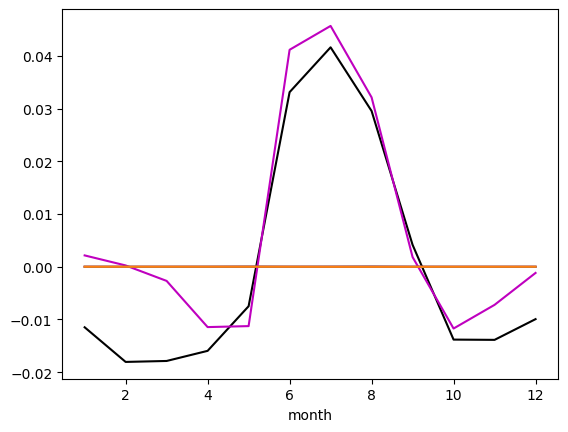

In [14]:
sea_flux_AS_8089.plot(c='k')
W_AS_8089.plot(c='m')
P_AS_8089.plot(c='r')
T_AS_8089.plot()
S_AS_8089.plot()

## WAS

In [15]:
pco2_WAS_8089 = pco2_8089.sel(LON=slice(30,65),LAT=slice(0,30)).mean(dim=['LAT','LON'])
pco2_atm_WAS_8089 = pco2_atm_8089.sel(LON=slice(30,65),LAT=slice(0,30)).mean(dim=['LAT','LON'])
temp_WAS_8089 = temp_8089.sel(LON=slice(30,65),LAT=slice(0,30)).mean(dim=['LAT','LON'])
sal_WAS_8089 = sal_8089.sel(LON=slice(30,65),LAT=slice(0,30)).mean(dim=['LAT','LON'])
ws_WAS_8089 = ws_8089.sel(LON=slice(30,65),LAT=slice(0,30)).mean(dim=['LAT','LON'])

flux_WAS_8089 = air_sea_CO2_flux(temp_WAS_8089, sal_WAS_8089, ws_WAS_8089, pco2_WAS_8089, pco2_atm_WAS_8089)*area_WAS*(12.0 / 1e15)
sea_flux_WAS_8089 = flux_WAS_8089 - flux_WAS_8089.mean()

temp_WAS_8089_dev = temp_WAS_8089 + 0.0001*temp_WAS_8089.mean()
flux_T_WAS_8089 = air_sea_CO2_flux(temp_WAS_8089_dev, sal_WAS_8089, ws_WAS_8089, pco2_WAS_8089, pco2_atm_WAS_8089)*area_WAS*(12.0 / 1e15)
T_WAS_8089 = ((flux_T_WAS_8089-flux_WAS_8089)/(0.0001*temp_WAS_8089))*(temp_WAS_8089 - temp_WAS_8089.mean())

sal_WAS_8089_dev = sal_WAS_8089 + 0.0001*sal_WAS_8089.mean()
flux_S_WAS_8089 = air_sea_CO2_flux(temp_WAS_8089, sal_WAS_8089_dev, ws_WAS_8089, pco2_WAS_8089, pco2_atm_WAS_8089)*area_WAS*(12.0 / 1e15)
S_WAS_8089 = ((flux_S_WAS_8089-flux_WAS_8089)/(0.0001*sal_WAS_8089.mean()))*(sal_WAS_8089 - sal_WAS_8089.mean())

ws_WAS_8089_dev = ws_WAS_8089 + 0.0001*ws_WAS_8089.mean()
flux_WS_WAS_8089 = air_sea_CO2_flux(temp_WAS_8089, sal_WAS_8089, ws_WAS_8089_dev, pco2_WAS_8089, pco2_atm_WAS_8089)*area_WAS*(12.0 / 1e15)
W_WAS_8089 = ((flux_WS_WAS_8089-flux_WAS_8089)/(0.0001*ws_WAS_8089.mean()))*(ws_WAS_8089 - ws_WAS_8089.mean())

pco2_WAS_8089_dev = pco2_WAS_8089 + 0.0001*pco2_WAS_8089.mean()
pco2_atm_WAS_8089_dev = pco2_atm_WAS_8089 + 0.0001*pco2_atm_WAS_8089.mean()
flux_P_WAS_8089 = air_sea_CO2_flux(temp_WAS_8089, sal_WAS_8089, ws_WAS_8089, pco2_WAS_8089_dev, pco2_atm_WAS_8089_dev)*area_WAS*(12.0 / 1e15)
P_WAS_8089 = ((flux_P_WAS_8089-flux_WAS_8089)/(0.0001*(pco2_WAS_8089-pco2_atm_WAS_8089).mean()))*((pco2_WAS_8089-pco2_WAS_8089.mean()) - (pco2_atm_WAS_8089-pco2_atm_WAS_8089.mean()))

In [16]:
W_imp_WAS_8089 = W_WAS_8089.max() - W_WAS_8089.min()
P_imp_WAS_8089 = P_WAS_8089.max() - P_WAS_8089.min()
T_imp_WAS_8089 = T_WAS_8089.max() - T_WAS_8089.min()
S_imp_WAS_8089 = S_WAS_8089.max() - S_WAS_8089.min()

print(f"Wind_imp_WAS: {W_imp_WAS_8089:.2f} PgC yr⁻¹")
print(f"pco2_imp_WAS: {P_imp_WAS_8089:.2f} PgC yr⁻¹")
print(f"temp_imp_WAS: {T_imp_WAS_8089:.2f} PgC yr⁻¹")
print(f"sal_imp_WAS: {S_imp_WAS_8089:.2f} PgC yr⁻¹")

Wind_imp_WAS: 0.05 PgC yr⁻¹
pco2_imp_WAS: 0.02 PgC yr⁻¹
temp_imp_WAS: 0.00 PgC yr⁻¹
sal_imp_WAS: 0.00 PgC yr⁻¹


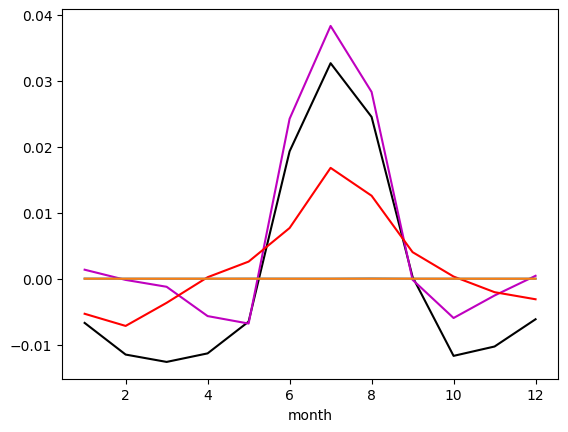

In [17]:
sea_flux_WAS_8089.plot(c='k')
W_WAS_8089.plot(c='m')
P_WAS_8089.plot(c='r')
T_WAS_8089.plot()
S_WAS_8089.plot()

## EAS

In [18]:
pco2_EAS_8089 = pco2_8089.sel(LON=slice(65,78),LAT=slice(0,30)).mean(dim=['LAT','LON'])
pco2_atm_EAS_8089 = pco2_atm_8089.sel(LON=slice(65,78),LAT=slice(0,30)).mean(dim=['LAT','LON'])
temp_EAS_8089 = temp_8089.sel(LON=slice(65,78),LAT=slice(0,30)).mean(dim=['LAT','LON'])
sal_EAS_8089 = sal_8089.sel(LON=slice(65,78),LAT=slice(0,30)).mean(dim=['LAT','LON'])
ws_EAS_8089 = ws_8089.sel(LON=slice(65,78),LAT=slice(0,30)).mean(dim=['LAT','LON'])

flux_EAS_8089 = air_sea_CO2_flux(temp_EAS_8089, sal_EAS_8089, ws_EAS_8089, pco2_EAS_8089, pco2_atm_EAS_8089)*area_EAS*(12.0 / 1e15)
sea_flux_EAS_8089 = flux_EAS_8089 - flux_EAS_8089.mean()

temp_EAS_8089_dev = temp_EAS_8089 + 0.0001*temp_EAS_8089.mean()
flux_T_EAS_8089 = air_sea_CO2_flux(temp_EAS_8089_dev, sal_EAS_8089, ws_EAS_8089, pco2_EAS_8089, pco2_atm_EAS_8089)*area_EAS*(12.0 / 1e15)
T_EAS_8089 = ((flux_T_EAS_8089-flux_EAS_8089)/(0.0001*temp_EAS_8089))*(temp_EAS_8089 - temp_EAS_8089.mean())

sal_EAS_8089_dev = sal_EAS_8089 + 0.0001*sal_EAS_8089.mean()
flux_S_EAS_8089 = air_sea_CO2_flux(temp_EAS_8089, sal_EAS_8089_dev, ws_EAS_8089, pco2_EAS_8089, pco2_atm_EAS_8089)*area_EAS*(12.0 / 1e15)
S_EAS_8089 = ((flux_S_EAS_8089-flux_EAS_8089)/(0.0001*sal_EAS_8089.mean()))*(sal_EAS_8089 - sal_EAS_8089.mean())

ws_EAS_8089_dev = ws_EAS_8089 + 0.0001*ws_EAS_8089.mean()
flux_WS_EAS_8089 = air_sea_CO2_flux(temp_EAS_8089, sal_EAS_8089, ws_EAS_8089_dev, pco2_EAS_8089, pco2_atm_EAS_8089)*area_EAS*(12.0 / 1e15)
W_EAS_8089 = ((flux_WS_EAS_8089-flux_EAS_8089)/(0.0001*ws_EAS_8089.mean()))*(ws_EAS_8089 - ws_EAS_8089.mean())

pco2_EAS_8089_dev = pco2_EAS_8089 + 0.0001*pco2_EAS_8089.mean()
pco2_atm_EAS_8089_dev = pco2_atm_EAS_8089 + 0.0001*pco2_atm_EAS_8089.mean()
flux_P_EAS_8089 = air_sea_CO2_flux(temp_EAS_8089, sal_EAS_8089, ws_EAS_8089, pco2_EAS_8089_dev, pco2_atm_EAS_8089_dev)*area_EAS*(12.0 / 1e15)
P_EAS_8089 = ((flux_P_EAS_8089-flux_EAS_8089)/(0.0001*(pco2_EAS_8089-pco2_atm_EAS_8089).mean()))*((pco2_EAS_8089-pco2_EAS_8089.mean()) - (pco2_atm_EAS_8089-pco2_atm_EAS_8089.mean()))

In [19]:
W_imp_EAS_8089 = W_EAS_8089.max() - W_EAS_8089.min()
P_imp_EAS_8089 = P_EAS_8089.max() - P_EAS_8089.min()
T_imp_EAS_8089 = T_EAS_8089.max() - T_EAS_8089.min()
S_imp_EAS_8089 = S_EAS_8089.max() - S_EAS_8089.min()

print(f"Wind_imp_EAS: {W_imp_EAS_8089:.2f} PgC yr⁻¹")
print(f"pco2_imp_EAS: {P_imp_EAS_8089:.2f} PgC yr⁻¹")
print(f"temp_imp_EAS: {T_imp_EAS_8089:.2f} PgC yr⁻¹")
print(f"sal_imp_EAS: {S_imp_EAS_8089:.2f} PgC yr⁻¹")

Wind_imp_EAS: 0.03 PgC yr⁻¹
pco2_imp_EAS: 0.02 PgC yr⁻¹
temp_imp_EAS: 0.00 PgC yr⁻¹
sal_imp_EAS: 0.00 PgC yr⁻¹


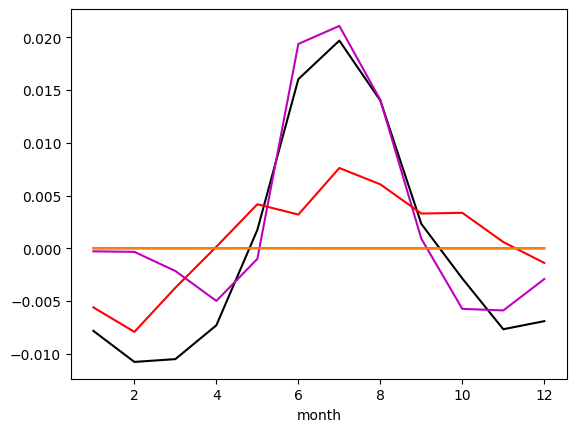

In [20]:
sea_flux_EAS_8089.plot(c='k')
W_EAS_8089.plot(c='m')
P_EAS_8089.plot(c='r')
T_EAS_8089.plot()
S_EAS_8089.plot()

## BoB

In [21]:
pco2_BoB_8089 = pco2_8089.sel(LON=slice(78,110),LAT=slice(0,30)).mean(dim=['LAT','LON'])
pco2_atm_BoB_8089 = pco2_atm_8089.sel(LON=slice(78,110),LAT=slice(0,30)).mean(dim=['LAT','LON'])
temp_BoB_8089 = temp_8089.sel(LON=slice(78,110),LAT=slice(0,30)).mean(dim=['LAT','LON'])
sal_BoB_8089 = sal_8089.sel(LON=slice(78,110),LAT=slice(0,30)).mean(dim=['LAT','LON'])
ws_BoB_8089 = ws_8089.sel(LON=slice(78,110),LAT=slice(0,30)).mean(dim=['LAT','LON'])

flux_BoB_8089 = air_sea_CO2_flux(temp_BoB_8089, sal_BoB_8089, ws_BoB_8089, pco2_BoB_8089, pco2_atm_BoB_8089)*area_BoB*(12.0 / 1e15)
sea_flux_BoB_8089 = flux_BoB_8089 - flux_BoB_8089.mean()

temp_BoB_8089_dev = temp_BoB_8089 + 0.0001*temp_BoB_8089.mean()
flux_T_BoB_8089 = air_sea_CO2_flux(temp_BoB_8089_dev, sal_BoB_8089, ws_BoB_8089, pco2_BoB_8089, pco2_atm_BoB_8089)*area_BoB*(12.0 / 1e15)
der_T_BoB_8089 = ((flux_T_BoB_8089-flux_BoB_8089)/(0.0001*temp_BoB_8089))
anm_T_BoB_8089 = (temp_BoB_8089 - temp_BoB_8089.mean())
T_BoB_8089 = der_T_AS_8089*anm_T_AS_8089
# T_BoB_8089 = ((flux_T_BoB_8089-flux_BoB_8089)/(0.0001*temp_BoB_8089))*(temp_BoB_8089 - temp_BoB_8089.mean())

sal_BoB_8089_dev = sal_BoB_8089 + 0.0001*sal_BoB_8089.mean()
flux_S_BoB_8089 = air_sea_CO2_flux(temp_BoB_8089, sal_BoB_8089_dev, ws_BoB_8089, pco2_BoB_8089, pco2_atm_BoB_8089)*area_BoB*(12.0 / 1e15)
der_S_BoB_8089 = ((flux_S_BoB_8089-flux_BoB_8089)/(0.0001*sal_BoB_8089.mean()))
anm_S_BoB_8089 = (sal_BoB_8089 - sal_BoB_8089.mean())
S_BoB_8089 = der_S_AS_8089*anm_S_AS_8089
# S_BoB_8089 = ((flux_S_BoB_8089-flux_BoB_8089)/(0.0001*sal_BoB_8089.mean()))*(sal_BoB_8089 - sal_BoB_8089.mean())

ws_BoB_8089_dev = ws_BoB_8089 + 0.0001*ws_BoB_8089.mean()
flux_WS_BoB_8089 = air_sea_CO2_flux(temp_BoB_8089, sal_BoB_8089, ws_BoB_8089_dev, pco2_BoB_8089, pco2_atm_BoB_8089)*area_BoB*(12.0 / 1e15)
der_W_BoB_8089 = ((flux_WS_BoB_8089-flux_BoB_8089)/(0.0001*ws_BoB_8089.mean()))
anm_W_BoB_8089 = (ws_BoB_8089 - ws_BoB_8089.mean())
W_BoB_8089 = der_W_BoB_8089*anm_W_BoB_8089
# W_BoB_8089 = ((flux_WS_BoB_8089-flux_BoB_8089)/(0.0001*ws_BoB_8089.mean()))*(ws_BoB_8089 - ws_BoB_8089.mean())

pco2_BoB_8089_dev = pco2_BoB_8089 + 0.0001*pco2_BoB_8089.mean()
pco2_atm_BoB_8089_dev = pco2_atm_BoB_8089 + 0.0001*pco2_atm_BoB_8089.mean()
flux_P_BoB_8089 = air_sea_CO2_flux(temp_BoB_8089, sal_BoB_8089, ws_BoB_8089, pco2_BoB_8089_dev, pco2_atm_BoB_8089_dev)*area_BoB*(12.0 / 1e15)
der_P_BoB_8089 = ((flux_P_BoB_8089-flux_BoB_8089)/(0.0001*(pco2_BoB_8089-pco2_atm_BoB_8089).mean()))
anm_P_BoB_8089 = ((pco2_BoB_8089-pco2_BoB_8089.mean()) - (pco2_atm_BoB_8089-pco2_atm_BoB_8089.mean()))
P_BoB_8089 = der_P_BoB_8089*anm_P_BoB_8089
# P_BoB_8089 = ((flux_P_BoB_8089-flux_BoB_8089)/(0.0001*(pco2_BoB_8089-pco2_atm_BoB_8089).mean()))*((pco2_BoB_8089-pco2_BoB_8089.mean()) - (pco2_atm_BoB_8089-pco2_atm_BoB_8089.mean()))

In [22]:
W_imp_BoB_8089 = W_BoB_8089.max() - W_BoB_8089.min()
P_imp_BoB_8089 = P_BoB_8089.max() - P_BoB_8089.min()
T_imp_BoB_8089 = T_BoB_8089.max() - T_BoB_8089.min()
S_imp_BoB_8089 = S_BoB_8089.max() - S_BoB_8089.min()

print(f"Wind_imp_BoB: {W_imp_BoB_8089:.2f} PgC yr⁻¹")
print(f"pco2_imp_BoB: {P_imp_BoB_8089:.2f} PgC yr⁻¹")
print(f"temp_imp_BoB: {T_imp_BoB_8089:.2f} PgC yr⁻¹")
print(f"sal_imp_BoB: {S_imp_BoB_8089:.2f} PgC yr⁻¹")

Wind_imp_BoB: 0.01 PgC yr⁻¹
pco2_imp_BoB: 0.01 PgC yr⁻¹
temp_imp_BoB: 0.00 PgC yr⁻¹
sal_imp_BoB: 0.00 PgC yr⁻¹


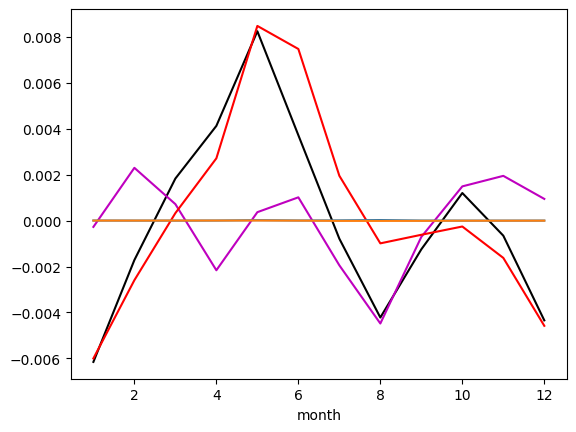

In [23]:
sea_flux_BoB_8089.plot(c='k')
W_BoB_8089.plot(c='m')
P_BoB_8089.plot(c='r')
T_BoB_8089.plot()
S_BoB_8089.plot()

## NBoB

In [24]:
pco2_NBoB_8089 = pco2_8089.sel(LON=slice(78,110),LAT=slice(15,30)).mean(dim=['LAT','LON'])
pco2_atm_NBoB_8089 = pco2_atm_8089.sel(LON=slice(78,110),LAT=slice(15,30)).mean(dim=['LAT','LON'])
temp_NBoB_8089 = temp_8089.sel(LON=slice(78,110),LAT=slice(15,30)).mean(dim=['LAT','LON'])
sal_NBoB_8089 = sal_8089.sel(LON=slice(78,110),LAT=slice(15,30)).mean(dim=['LAT','LON'])
ws_NBoB_8089 = ws_8089.sel(LON=slice(78,110),LAT=slice(15,30)).mean(dim=['LAT','LON'])

flux_NBoB_8089 = air_sea_CO2_flux(temp_NBoB_8089, sal_NBoB_8089, ws_NBoB_8089, pco2_NBoB_8089, pco2_atm_NBoB_8089)*area_NBoB*(12.0 / 1e15)
sea_flux_NBoB_8089 = flux_NBoB_8089 - flux_NBoB_8089.mean()

temp_NBoB_8089_dev = temp_NBoB_8089 + 0.0001*temp_NBoB_8089.mean()
flux_T_NBoB_8089 = air_sea_CO2_flux(temp_NBoB_8089_dev, sal_NBoB_8089, ws_NBoB_8089, pco2_NBoB_8089, pco2_atm_NBoB_8089)*area_NBoB*(12.0 / 1e15)
T_NBoB_8089 = ((flux_T_NBoB_8089-flux_NBoB_8089)/(0.0001*temp_NBoB_8089))*(temp_NBoB_8089 - temp_NBoB_8089.mean())

sal_NBoB_8089_dev = sal_NBoB_8089 + 0.0001*sal_NBoB_8089.mean()
flux_S_NBoB_8089 = air_sea_CO2_flux(temp_NBoB_8089, sal_NBoB_8089_dev, ws_NBoB_8089, pco2_NBoB_8089, pco2_atm_NBoB_8089)*area_NBoB*(12.0 / 1e15)
S_NBoB_8089 = ((flux_S_NBoB_8089-flux_NBoB_8089)/(0.0001*sal_NBoB_8089.mean()))*(sal_NBoB_8089 - sal_NBoB_8089.mean())

ws_NBoB_8089_dev = ws_NBoB_8089 + 0.0001*ws_NBoB_8089.mean()
flux_WS_NBoB_8089 = air_sea_CO2_flux(temp_NBoB_8089, sal_NBoB_8089, ws_NBoB_8089_dev, pco2_NBoB_8089, pco2_atm_NBoB_8089)*area_NBoB*(12.0 / 1e15)
W_NBoB_8089 = ((flux_WS_NBoB_8089-flux_NBoB_8089)/(0.0001*ws_NBoB_8089.mean()))*(ws_NBoB_8089 - ws_NBoB_8089.mean())

pco2_NBoB_8089_dev = pco2_NBoB_8089 + 0.0001*pco2_NBoB_8089.mean()
pco2_atm_NBoB_8089_dev = pco2_atm_NBoB_8089 + 0.0001*pco2_atm_NBoB_8089.mean()
flux_P_NBoB_8089 = air_sea_CO2_flux(temp_NBoB_8089, sal_NBoB_8089, ws_NBoB_8089, pco2_NBoB_8089_dev, pco2_atm_NBoB_8089_dev)*area_NBoB*(12.0 / 1e15)
P_NBoB_8089 = ((flux_P_NBoB_8089-flux_NBoB_8089)/(0.0001*(pco2_NBoB_8089-pco2_atm_NBoB_8089).mean()))*((pco2_NBoB_8089-pco2_NBoB_8089.mean()) - (pco2_atm_NBoB_8089-pco2_atm_NBoB_8089.mean()))

In [25]:
W_imp_NBoB_8089 = W_NBoB_8089.max() - W_NBoB_8089.min()
P_imp_NBoB_8089 = P_NBoB_8089.max() - P_NBoB_8089.min()
T_imp_NBoB_8089 = T_NBoB_8089.max() - T_NBoB_8089.min()
S_imp_NBoB_8089 = S_NBoB_8089.max() - S_NBoB_8089.min()

print(f"Wind_imp_NBoB: {W_imp_NBoB_8089:.2f} PgC yr⁻¹")
print(f"pco2_imp_NBoB: {P_imp_NBoB_8089:.2f} PgC yr⁻¹")
print(f"temp_imp_NBoB: {T_imp_NBoB_8089:.2f} PgC yr⁻¹")
print(f"sal_imp_NBoB: {S_imp_NBoB_8089:.2f} PgC yr⁻¹")

Wind_imp_NBoB: 0.00 PgC yr⁻¹
pco2_imp_NBoB: 0.01 PgC yr⁻¹
temp_imp_NBoB: 0.00 PgC yr⁻¹
sal_imp_NBoB: 0.00 PgC yr⁻¹


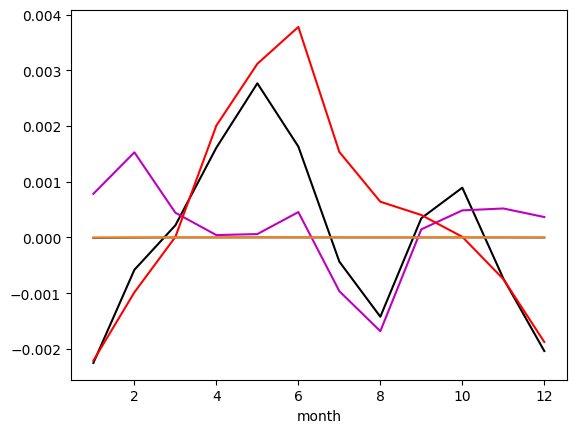

In [26]:
sea_flux_NBoB_8089.plot(c='k')
W_NBoB_8089.plot(c='m')
P_NBoB_8089.plot(c='r')
T_NBoB_8089.plot()
S_NBoB_8089.plot()

## SBoB

In [27]:
pco2_SBoB_8089 = pco2_8089.sel(LON=slice(78,110),LAT=slice(0,15)).mean(dim=['LAT','LON'])
pco2_atm_SBoB_8089 = pco2_atm_8089.sel(LON=slice(78,110),LAT=slice(0,15)).mean(dim=['LAT','LON'])
temp_SBoB_8089 = temp_8089.sel(LON=slice(78,110),LAT=slice(0,15)).mean(dim=['LAT','LON'])
sal_SBoB_8089 = sal_8089.sel(LON=slice(78,110),LAT=slice(0,15)).mean(dim=['LAT','LON'])
ws_SBoB_8089 = ws_8089.sel(LON=slice(78,110),LAT=slice(0,15)).mean(dim=['LAT','LON'])

flux_SBoB_8089 = air_sea_CO2_flux(temp_SBoB_8089, sal_SBoB_8089, ws_SBoB_8089, pco2_SBoB_8089, pco2_atm_SBoB_8089)*area_SBoB*(12.0 / 1e15)
sea_flux_SBoB_8089 = flux_SBoB_8089 - flux_SBoB_8089.mean()

temp_SBoB_8089_dev = temp_SBoB_8089 + 0.0001*temp_SBoB_8089.mean()
flux_T_SBoB_8089 = air_sea_CO2_flux(temp_SBoB_8089_dev, sal_SBoB_8089, ws_SBoB_8089, pco2_SBoB_8089, pco2_atm_SBoB_8089)*area_SBoB*(12.0 / 1e15)
T_SBoB_8089 = ((flux_T_SBoB_8089-flux_SBoB_8089)/(0.0001*temp_SBoB_8089))*(temp_SBoB_8089 - temp_SBoB_8089.mean())

sal_SBoB_8089_dev = sal_SBoB_8089 + 0.0001*sal_SBoB_8089.mean()
flux_S_SBoB_8089 = air_sea_CO2_flux(temp_SBoB_8089, sal_SBoB_8089_dev, ws_SBoB_8089, pco2_SBoB_8089, pco2_atm_SBoB_8089)*area_SBoB*(12.0 / 1e15)
S_SBoB_8089 = ((flux_S_SBoB_8089-flux_SBoB_8089)/(0.0001*sal_SBoB_8089.mean()))*(sal_SBoB_8089 - sal_SBoB_8089.mean())

ws_SBoB_8089_dev = ws_SBoB_8089 + 0.0001*ws_SBoB_8089.mean()
flux_WS_SBoB_8089 = air_sea_CO2_flux(temp_SBoB_8089, sal_SBoB_8089, ws_SBoB_8089_dev, pco2_SBoB_8089, pco2_atm_SBoB_8089)*area_SBoB*(12.0 / 1e15)
W_SBoB_8089 = ((flux_WS_SBoB_8089-flux_SBoB_8089)/(0.0001*ws_SBoB_8089.mean()))*(ws_SBoB_8089 - ws_SBoB_8089.mean())

pco2_SBoB_8089_dev = pco2_SBoB_8089 + 0.0001*pco2_SBoB_8089.mean()
pco2_atm_SBoB_8089_dev = pco2_atm_SBoB_8089 + 0.0001*pco2_atm_SBoB_8089.mean()
flux_P_SBoB_8089 = air_sea_CO2_flux(temp_SBoB_8089, sal_SBoB_8089, ws_SBoB_8089, pco2_SBoB_8089_dev, pco2_atm_SBoB_8089_dev)*area_SBoB*(12.0 / 1e15)
P_SBoB_8089 = ((flux_P_SBoB_8089-flux_SBoB_8089)/(0.0001*(pco2_SBoB_8089-pco2_atm_SBoB_8089).mean()))*((pco2_SBoB_8089-pco2_SBoB_8089.mean()) - (pco2_atm_SBoB_8089-pco2_atm_SBoB_8089.mean()))

In [28]:
W_imp_SBoB_8089 = W_SBoB_8089.max() - W_SBoB_8089.min()
P_imp_SBoB_8089 = P_SBoB_8089.max() - P_SBoB_8089.min()
T_imp_SBoB_8089 = T_SBoB_8089.max() - T_SBoB_8089.min()
S_imp_SBoB_8089 = S_SBoB_8089.max() - S_SBoB_8089.min()

print(f"Wind_imp_SBoB: {W_imp_SBoB_8089:.2f} PgC yr⁻¹")
print(f"pco2_imp_SBoB: {P_imp_SBoB_8089:.2f} PgC yr⁻¹")
print(f"temp_imp_SBoB: {T_imp_SBoB_8089:.2f} PgC yr⁻¹")
print(f"sal_imp_SBoB: {S_imp_SBoB_8089:.2f} PgC yr⁻¹")

Wind_imp_SBoB: 0.00 PgC yr⁻¹
pco2_imp_SBoB: 0.01 PgC yr⁻¹
temp_imp_SBoB: 0.00 PgC yr⁻¹
sal_imp_SBoB: 0.00 PgC yr⁻¹


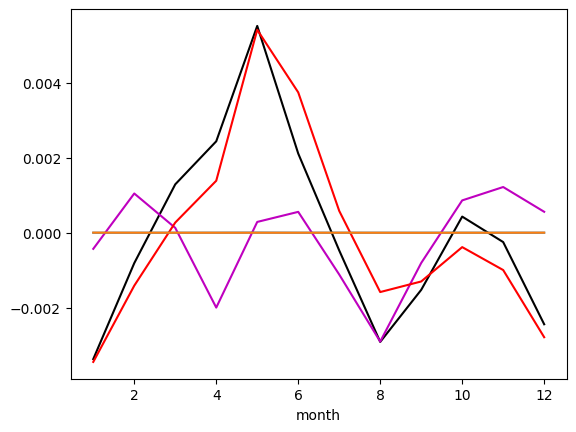

In [29]:
sea_flux_SBoB_8089.plot(c='k')
W_SBoB_8089.plot(c='m')
P_SBoB_8089.plot(c='r')
T_SBoB_8089.plot()
S_SBoB_8089.plot()

## EIO

In [30]:
pco2_EIO_8089 = pco2_8089.sel(LON=slice(30,120),LAT=slice(-18,0)).mean(dim=['LAT','LON'])
pco2_atm_EIO_8089 = pco2_atm_8089.sel(LON=slice(30,120),LAT=slice(-18,0)).mean(dim=['LAT','LON'])
temp_EIO_8089 = temp_8089.sel(LON=slice(30,120),LAT=slice(-18,0)).mean(dim=['LAT','LON'])
sal_EIO_8089 = sal_8089.sel(LON=slice(30,120),LAT=slice(-18,0)).mean(dim=['LAT','LON'])
ws_EIO_8089 = ws_8089.sel(LON=slice(30,120),LAT=slice(-18,0)).mean(dim=['LAT','LON'])

flux_EIO_8089 = air_sea_CO2_flux(temp_EIO_8089, sal_EIO_8089, ws_EIO_8089, pco2_EIO_8089, pco2_atm_EIO_8089)*area_EIO*(12.0 / 1e15)
sea_flux_EIO_8089 = flux_EIO_8089 - flux_EIO_8089.mean()

temp_EIO_8089_dev = temp_EIO_8089 + 0.0001*temp_EIO_8089.mean()
flux_T_EIO_8089 = air_sea_CO2_flux(temp_EIO_8089_dev, sal_EIO_8089, ws_EIO_8089, pco2_EIO_8089, pco2_atm_EIO_8089)*area_EIO*(12.0 / 1e15)
der_T_EIO_8089 = ((flux_T_EIO_8089-flux_EIO_8089)/(0.0001*temp_EIO_8089.mean()))
anm_T_EIO_8089 = (temp_EIO_8089 - temp_EIO_8089.mean())
T_EIO_8089 = der_T_EIO_8089*anm_T_EIO_8089

sal_EIO_8089_dev = sal_EIO_8089 + 0.0001*sal_EIO_8089.mean()
flux_S_EIO_8089 = air_sea_CO2_flux(temp_EIO_8089, sal_EIO_8089_dev, ws_EIO_8089, pco2_EIO_8089, pco2_atm_EIO_8089)*area_EIO*(12.0 / 1e15)
der_S_EIO_8089 = ((flux_S_EIO_8089-flux_EIO_8089)/(0.0001*sal_EIO_8089.mean()))
anm_S_EIO_8089 = (sal_EIO_8089 - sal_EIO_8089.mean())
S_EIO_8089 = ((flux_S_EIO_8089-flux_EIO_8089)/(0.0001*sal_EIO_8089.mean()))*(sal_EIO_8089 - sal_EIO_8089.mean())

ws_EIO_8089_dev = ws_EIO_8089 + 0.0001*ws_EIO_8089.mean()
flux_WS_EIO_8089 = air_sea_CO2_flux(temp_EIO_8089, sal_EIO_8089, ws_EIO_8089_dev, pco2_EIO_8089, pco2_atm_EIO_8089)*area_EIO*(12.0 / 1e15)
der_W_EIO_8089 = ((flux_WS_EIO_8089-flux_EIO_8089)/(0.0001*ws_EIO_8089.mean()))
anm_W_EIO_8089 = (ws_EIO_8089 - ws_EIO_8089.mean())
W_EIO_8089 = der_W_EIO_8089*anm_W_EIO_8089

pco2_EIO_8089_dev = pco2_EIO_8089 + 0.0001*pco2_EIO_8089.mean()
pco2_atm_EIO_8089_dev = pco2_atm_EIO_8089 + 0.0001*pco2_atm_EIO_8089.mean()
flux_P_EIO_8089 = air_sea_CO2_flux(temp_EIO_8089, sal_EIO_8089, ws_EIO_8089, pco2_EIO_8089_dev, pco2_atm_EIO_8089_dev)*area_EIO*(12.0 / 1e15)
der_P_EIO_8089 = ((flux_P_EIO_8089-flux_EIO_8089)/(0.0001*(pco2_EIO_8089-pco2_atm_EIO_8089).mean()))
anm_P_EIO_8089 = ((pco2_EIO_8089-pco2_EIO_8089.mean()) - (pco2_atm_EIO_8089-pco2_atm_EIO_8089.mean()))
P_EIO_8089 = der_P_EIO_8089*anm_P_EIO_8089

In [31]:
W_imp_EIO_8089 = W_EIO_8089.max() - W_EIO_8089.min()
P_imp_EIO_8089 = P_EIO_8089.max() - P_EIO_8089.min()
T_imp_EIO_8089 = T_EIO_8089.max() - T_EIO_8089.min()
S_imp_EIO_8089 = S_EIO_8089.max() - S_EIO_8089.min()

print(f"Wind_imp_EIO: {W_imp_EIO_8089:.2f} PgC yr⁻¹")
print(f"pco2_imp_EIO: {P_imp_EIO_8089:.2f} PgC yr⁻¹")
print(f"temp_imp_EIO: {T_imp_EIO_8089:.2f} PgC yr⁻¹")
print(f"sal_imp_EIO: {S_imp_EIO_8089:.2f} PgC yr⁻¹")

Wind_imp_EIO: 0.03 PgC yr⁻¹
pco2_imp_EIO: 0.07 PgC yr⁻¹
temp_imp_EIO: 0.00 PgC yr⁻¹
sal_imp_EIO: 0.00 PgC yr⁻¹


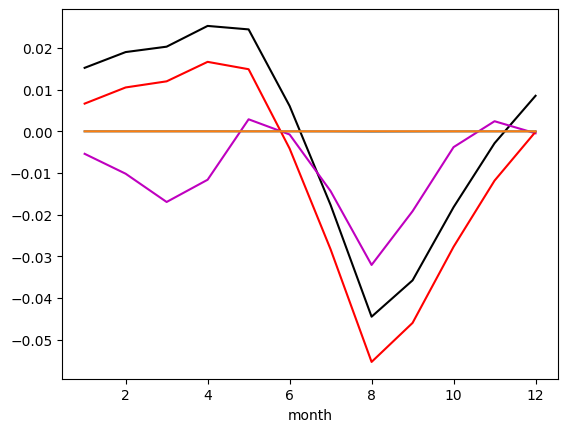

In [32]:
sea_flux_EIO_8089.plot(c='k')
W_EIO_8089.plot(c='m')
P_EIO_8089.plot(c='r')
T_EIO_8089.plot()
S_EIO_8089.plot()

## SIO

In [33]:
pco2_SIO_8089 = pco2_8089.sel(LON=slice(30,120),LAT=slice(-30,-18)).mean(dim=['LAT','LON'])
pco2_atm_SIO_8089 = pco2_atm_8089.sel(LON=slice(30,120),LAT=slice(-30,-18)).mean(dim=['LAT','LON'])
temp_SIO_8089 = temp_8089.sel(LON=slice(30,120),LAT=slice(-30,-18)).mean(dim=['LAT','LON'])
sal_SIO_8089 = sal_8089.sel(LON=slice(30,120),LAT=slice(-30,-18)).mean(dim=['LAT','LON'])
ws_SIO_8089 = ws_8089.sel(LON=slice(30,120),LAT=slice(-30,-18)).mean(dim=['LAT','LON'])

flux_SIO_8089 = air_sea_CO2_flux(temp_SIO_8089, sal_SIO_8089, ws_SIO_8089, pco2_SIO_8089, pco2_atm_SIO_8089)*area_SIO*(12.0 / 1e15)
sea_flux_SIO_8089 = flux_SIO_8089 - flux_SIO_8089.mean()

temp_SIO_8089_dev = temp_SIO_8089 + 0.0001*temp_SIO_8089.mean()
flux_T_SIO_8089 = air_sea_CO2_flux(temp_SIO_8089_dev, sal_SIO_8089, ws_SIO_8089, pco2_SIO_8089, pco2_atm_SIO_8089)*area_SIO*(12.0 / 1e15)
der_T_SIO_8089 = ((flux_T_SIO_8089-flux_SIO_8089)/(0.0001*temp_SIO_8089.mean()))
anm_T_SIO_8089 = (temp_SIO_8089 - temp_SIO_8089.mean())
T_SIO_8089 = der_T_SIO_8089*anm_T_SIO_8089

sal_SIO_8089_dev = sal_SIO_8089 + 0.0001*sal_SIO_8089.mean()
flux_S_SIO_8089 = air_sea_CO2_flux(temp_SIO_8089, sal_SIO_8089_dev, ws_SIO_8089, pco2_SIO_8089, pco2_atm_SIO_8089)*area_SIO*(12.0 / 1e15)
der_S_SIO_8089 = ((flux_S_SIO_8089-flux_SIO_8089)/(0.0001*sal_SIO_8089.mean()))
anm_S_SIO_8089 = (sal_SIO_8089 - sal_SIO_8089.mean())
S_SIO_8089 = der_S_SIO_8089*anm_S_SIO_8089

ws_SIO_8089_dev = ws_SIO_8089 + 0.0001*ws_SIO_8089.mean()
flux_WS_SIO_8089 = air_sea_CO2_flux(temp_SIO_8089, sal_SIO_8089, ws_SIO_8089_dev, pco2_SIO_8089, pco2_atm_SIO_8089)*area_SIO*(12.0 / 1e15)
der_W_SIO_8089 = ((flux_WS_SIO_8089-flux_SIO_8089)/(0.0001*ws_SIO_8089.mean()))
anm_W_SIO_8089 = (ws_SIO_8089 - ws_SIO_8089.mean())
W_SIO_8089 = der_W_SIO_8089*anm_W_SIO_8089

pco2_SIO_8089_dev = pco2_SIO_8089 + 0.0001*pco2_SIO_8089.mean()
pco2_atm_SIO_8089_dev = pco2_atm_SIO_8089 + 0.0001*pco2_atm_SIO_8089.mean()
flux_P_SIO_8089 = air_sea_CO2_flux(temp_SIO_8089, sal_SIO_8089, ws_SIO_8089, pco2_SIO_8089_dev, pco2_atm_SIO_8089_dev)*area_SIO*(12.0 / 1e15)
der_P_SIO_8089 =  ((flux_P_SIO_8089-flux_SIO_8089)/(0.0001*(pco2_SIO_8089-pco2_atm_SIO_8089).mean()))
anm_P_SIO_8089 = ((pco2_SIO_8089-pco2_SIO_8089.mean()) - (pco2_atm_SIO_8089-pco2_atm_SIO_8089.mean()))
P_SIO_8089 = der_P_SIO_8089*anm_P_SIO_8089

In [34]:
W_imp_SIO_8089 = W_SIO_8089.max() - W_SIO_8089.min()
P_imp_SIO_8089 = P_SIO_8089.max() - P_SIO_8089.min()
T_imp_SIO_8089 = T_SIO_8089.max() - T_SIO_8089.min()
S_imp_SIO_8089 = S_SIO_8089.max() - S_SIO_8089.min()

print(f"Wind_imp_SIO: {W_imp_SIO_8089:.2f} PgC yr⁻¹")
print(f"pco2_imp_SIO: {P_imp_SIO_8089:.2f} PgC yr⁻¹")
print(f"temp_imp_SIO: {T_imp_SIO_8089:.2f} PgC yr⁻¹")
print(f"sal_imp_SIO: {S_imp_SIO_8089:.2f} PgC yr⁻¹")

Wind_imp_SIO: 0.02 PgC yr⁻¹
pco2_imp_SIO: 0.09 PgC yr⁻¹
temp_imp_SIO: 0.00 PgC yr⁻¹
sal_imp_SIO: 0.00 PgC yr⁻¹


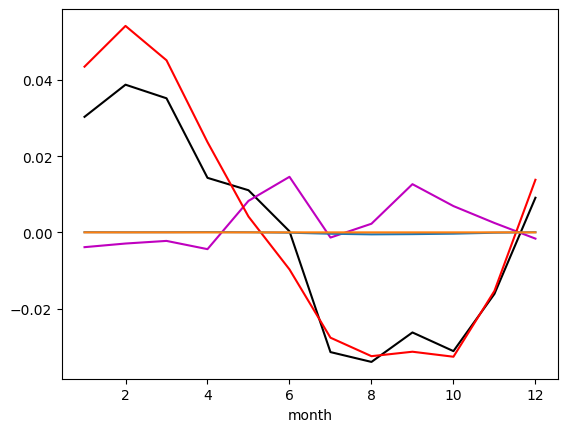

In [35]:
sea_flux_SIO_8089.plot(c='k')
W_SIO_8089.plot(c='m')
P_SIO_8089.plot(c='r')
T_SIO_8089.plot()
S_SIO_8089.plot()

## ESIO

In [36]:
# pco2_ESIO_8089 = pco2_8089.sel(LON=slice(75,120),LAT=slice(-30,-18)).mean(dim=['LAT','LON'])
# pco2_atm_ESIO_8089 = pco2_atm_8089.sel(LON=slice(75,120),LAT=slice(-30,-18)).mean(dim=['LAT','LON'])
# temp_ESIO_8089 = temp_8089.sel(LON=slice(75,120),LAT=slice(-30,-18)).mean(dim=['LAT','LON'])
# sal_ESIO_8089 = sal_8089.sel(LON=slice(75,120),LAT=slice(-30,-18)).mean(dim=['LAT','LON'])
# ws_ESIO_8089 = ws_8089.sel(LON=slice(75,120),LAT=slice(-30,-18)).mean(dim=['LAT','LON'])

# flux_ESIO_8089 = air_sea_CO2_flux(temp_ESIO_8089, sal_ESIO_8089, ws_ESIO_8089, pco2_ESIO_8089, pco2_atm_ESIO_8089)*area_ESIO*(12.0 / 1e15)
# sea_flux_ESIO_8089 = flux_ESIO_8089 - flux_ESIO_8089.mean()

# temp_ESIO_8089_dev = temp_ESIO_8089 + 0.0001*temp_ESIO_8089.mean()
# flux_T_ESIO_8089 = air_sea_CO2_flux(temp_ESIO_8089_dev, sal_ESIO_8089, ws_ESIO_8089, pco2_ESIO_8089, pco2_atm_ESIO_8089)*area_ESIO*(12.0 / 1e15)
# der_T_ESIO_8089 = ((flux_T_ESIO_8089-flux_ESIO_8089)/(0.0001*temp_ESIO_8089.mean()))
# anm_T_ESIO_8089 = (temp_ESIO_8089 - temp_ESIO_8089.mean())
# T_ESIO_8089 = der_T_ESIO_8089*anm_T_ESIO_8089

# sal_ESIO_8089_dev = sal_ESIO_8089 + 0.0001*sal_ESIO_8089.mean()
# flux_S_ESIO_8089 = air_sea_CO2_flux(temp_ESIO_8089, sal_ESIO_8089_dev, ws_ESIO_8089, pco2_ESIO_8089, pco2_atm_ESIO_8089)*area_ESIO*(12.0 / 1e15)
# der_S_ESIO_8089 = ((flux_S_ESIO_8089-flux_ESIO_8089)/(0.0001*sal_ESIO_8089.mean()))
# anm_S_ESIO_8089 = (sal_ESIO_8089 - sal_ESIO_8089.mean())
# S_ESIO_8089 = der_S_ESIO_8089*anm_S_ESIO_8089

# ws_ESIO_8089_dev = ws_ESIO_8089 + 0.0001*ws_ESIO_8089.mean()
# flux_WS_ESIO_8089 = air_sea_CO2_flux(temp_ESIO_8089, sal_ESIO_8089, ws_ESIO_8089_dev, pco2_ESIO_8089, pco2_atm_ESIO_8089)*area_ESIO*(12.0 / 1e15)
# der_W_ESIO_8089 = ((flux_WS_ESIO_8089-flux_ESIO_8089)/(0.0001*ws_ESIO_8089.mean()))
# anm_W_ESIO_8089 = (ws_ESIO_8089 - ws_ESIO_8089.mean())
# W_ESIO_8089 = der_W_ESIO_8089*anm_W_ESIO_8089

# pco2_ESIO_8089_dev = pco2_ESIO_8089 + 0.0001*pco2_ESIO_8089.mean()
# pco2_atm_ESIO_8089_dev = pco2_atm_ESIO_8089 + 0.0001*pco2_atm_ESIO_8089.mean()
# flux_P_ESIO_8089 = air_sea_CO2_flux(temp_ESIO_8089, sal_ESIO_8089, ws_ESIO_8089, pco2_ESIO_8089_dev, pco2_atm_ESIO_8089_dev)*area_ESIO*(12.0 / 1e15)
# der_P_ESIO_8089 =  ((flux_P_ESIO_8089-flux_ESIO_8089)/(0.0001*(pco2_ESIO_8089-pco2_atm_ESIO_8089).mean()))
# anm_P_ESIO_8089 = ((pco2_ESIO_8089-pco2_ESIO_8089.mean()) - (pco2_atm_ESIO_8089-pco2_atm_ESIO_8089.mean()))
# P_ESIO_8089 = der_P_ESIO_8089*anm_P_ESIO_8089

In [37]:
# W_imp_ESIO_8089 = W_ESIO_8089.max() - W_ESIO_8089.min()
# P_imp_ESIO_8089 = P_ESIO_8089.max() - P_ESIO_8089.min()
# T_imp_ESIO_8089 = T_ESIO_8089.max() - T_ESIO_8089.min()
# S_imp_ESIO_8089 = S_ESIO_8089.max() - S_ESIO_8089.min()

# print(f"Wind_imp_ESIO: {W_imp_ESIO_8089:.2f} PgC yr⁻¹")
# print(f"pco2_imp_ESIO: {P_imp_ESIO_8089:.2f} PgC yr⁻¹")
# print(f"temp_imp_ESIO: {T_imp_ESIO_8089:.2f} PgC yr⁻¹")
# print(f"sal_imp_ESIO: {S_imp_ESIO_8089:.2f} PgC yr⁻¹")

In [38]:
# sea_flux_ESIO_8089.plot(c='k')
# W_ESIO_8089.plot(c='m')
# P_ESIO_8089.plot(c='r')
# T_ESIO_8089.plot()
# S_ESIO_8089.plot()

# 1019

In [39]:
pco2_1019 = pco2.sel(TIME=slice('2010','2019')).groupby('TIME.month').mean() 
pco2_atm_1019 = pco2_atm.sel(TIME=slice('2010','2019')).groupby('TIME.month').mean() 
temp_1019 = temp.sel(TIME=slice('2010','2019')).groupby('TIME.month').mean() 
sal_1019 = sal.sel(TIME=slice('2010','2019')).groupby('TIME.month').mean() 
ws_1019 = ws.sel(TIME=slice('2010','2019')).groupby('TIME.month').mean() 

## AS

In [40]:
pco2_AS_1019 = pco2_1019.sel(LON=slice(30,78),LAT=slice(0,15)).mean(dim=['LAT','LON'])
pco2_atm_AS_1019 = pco2_atm_1019.sel(LON=slice(30,78),LAT=slice(0,15)).mean(dim=['LAT','LON'])
temp_AS_1019 = temp_1019.sel(LON=slice(30,78),LAT=slice(0,15)).mean(dim=['LAT','LON'])
sal_AS_1019 = sal_1019.sel(LON=slice(30,78),LAT=slice(0,15)).mean(dim=['LAT','LON'])
ws_AS_1019 = ws_1019.sel(LON=slice(30,78),LAT=slice(0,15)).mean(dim=['LAT','LON'])

flux_AS_1019 = air_sea_CO2_flux(temp_AS_1019, sal_AS_1019, ws_AS_1019, pco2_AS_1019, pco2_atm_AS_1019)*area_AS*(12.0 / 1e15)
sea_flux_AS_1019 = flux_AS_1019 - flux_AS_1019.mean()

temp_AS_1019_dev = temp_AS_1019 + 0.0001*temp_AS_1019.mean()
flux_T_AS_1019 = air_sea_CO2_flux(temp_AS_1019_dev, sal_AS_1019, ws_AS_1019, pco2_AS_1019, pco2_atm_AS_1019)*area_AS*(12.0 / 1e15)
der_T_AS_1019 = ((flux_T_AS_1019-flux_AS_1019)/(0.0001*temp_AS_1019.mean()))
anm_T_AS_1019 = (temp_AS_1019 - temp_AS_1019.mean())
T_AS_1019 = der_T_AS_1019*anm_T_AS_1019
# T_AS_1019 = ((flux_T_AS_1019-flux_AS_1019)/(0.0001*temp_AS_1019))*(temp_AS_1019 - temp_AS_1019.mean())

sal_AS_1019_dev = sal_AS_1019 + 0.0001*sal_AS_1019.mean()
flux_S_AS_1019 = air_sea_CO2_flux(temp_AS_1019, sal_AS_1019_dev, ws_AS_1019, pco2_AS_1019, pco2_atm_AS_1019)*area_AS*(12.0 / 1e15)
der_S_AS_1019 = ((flux_S_AS_1019-flux_AS_1019)/(0.0001*sal_AS_1019.mean()))
anm_S_AS_1019 = (sal_AS_1019 - sal_AS_1019.mean())
S_AS_1019 = der_S_AS_1019*anm_S_AS_1019
# S_AS_1019 = ((flux_S_AS_1019-flux_AS_1019)/(0.0001*sal_AS_1019.mean()))*(sal_AS_1019 - sal_AS_1019.mean())

ws_AS_1019_dev = ws_AS_1019 + 0.0001*ws_AS_1019.mean()
flux_WS_AS_1019 = air_sea_CO2_flux(temp_AS_1019, sal_AS_1019, ws_AS_1019_dev, pco2_AS_1019, pco2_atm_AS_1019)*area_AS*(12.0 / 1e15)
der_W_AS_1019 = ((flux_WS_AS_1019-flux_AS_1019)/(0.0001*ws_AS_1019.mean()))
anm_W_AS_1019 = (ws_AS_1019 - ws_AS_1019.mean())
W_AS_1019 = der_W_AS_1019*anm_W_AS_1019
# W_AS_1019 = ((flux_WS_AS_1019-flux_AS_1019)/(0.0001*ws_AS_1019.mean()))*(ws_AS_1019 - ws_AS_1019.mean())

pco2_AS_1019_dev = pco2_AS_1019 + 0.0001*pco2_AS_1019.mean()
pco2_atm_AS_1019_dev = pco2_atm_AS_1019 + 0.0001*pco2_atm_AS_1019.mean()
flux_P_AS_1019 = air_sea_CO2_flux(temp_AS_1019, sal_AS_1019, ws_AS_1019, pco2_AS_1019_dev, pco2_atm_AS_1019_dev)*area_AS*(12.0 / 1e15)
der_P_AS_1019 = ((flux_P_AS_1019-flux_AS_1019)/(0.0001*(pco2_AS_1019-pco2_atm_AS_1019).mean()))
anm_P_AS_1019 = ((pco2_AS_1019-pco2_AS_1019.mean()) - (pco2_atm_AS_1019-pco2_atm_AS_1019.mean()))
P_AS_1019 = der_P_AS_1019*anm_P_AS_1019
# P_AS_1019 = ((flux_P_AS_1019-flux_AS_1019)/(0.0001*(pco2_AS_1019-pco2_atm_AS_1019).mean()))*((pco2_AS_1019-pco2_AS_1019.mean()) - (pco2_atm_AS_1019-pco2_atm_AS_1019.mean()))

In [41]:
W_imp_AS_1019 = W_AS_1019.max() - W_AS_1019.min()
P_imp_AS_1019 = P_AS_1019.max() - P_AS_1019.min()
T_imp_AS_1019 = T_AS_1019.max() - T_AS_1019.min()
S_imp_AS_1019 = S_AS_1019.max() - S_AS_1019.min()

print(f"Wind_imp_AS: {W_imp_AS_1019:.2f} PgC yr⁻¹")
print(f"pco2_imp_AS: {P_imp_AS_1019:.2f} PgC yr⁻¹")
print(f"temp_imp_AS: {T_imp_AS_1019:.2f} PgC yr⁻¹")
print(f"sal_imp_AS: {S_imp_AS_1019:.2f} PgC yr⁻¹")

Wind_imp_AS: 0.04 PgC yr⁻¹
pco2_imp_AS: 0.02 PgC yr⁻¹
temp_imp_AS: 0.00 PgC yr⁻¹
sal_imp_AS: 0.00 PgC yr⁻¹


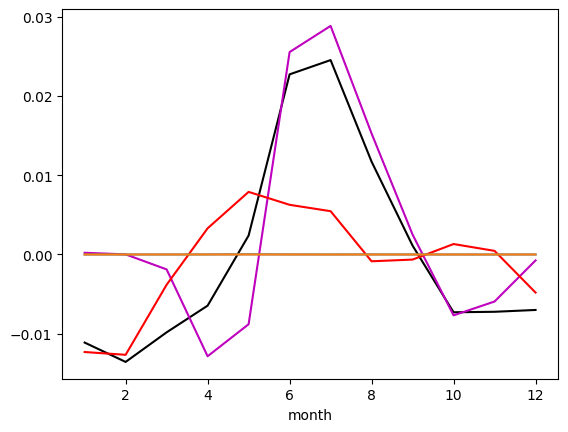

In [42]:
sea_flux_AS_1019.plot(c='k')
W_AS_1019.plot(c='m')
P_AS_1019.plot(c='r')
T_AS_1019.plot()
S_AS_1019.plot()

In [43]:
T_sen_AS = (anm_T_AS_8089*(der_T_AS_1019-der_T_AS_8089))
T_driver_AS = ((anm_T_AS_1019-anm_T_AS_8089)*der_T_AS_8089)

S_sen_AS = (anm_S_AS_8089*(der_S_AS_1019-der_S_AS_8089))
S_driver_AS = ((anm_S_AS_1019-anm_S_AS_8089)*der_S_AS_8089)

W_sen_AS = (anm_W_AS_8089*(der_W_AS_1019-der_W_AS_8089))
W_driver_AS = ((anm_W_AS_1019-anm_W_AS_8089)*der_W_AS_8089)

P_sen_AS = (anm_P_AS_8089*(der_P_AS_1019-der_P_AS_8089))
P_driver_AS = ((anm_P_AS_1019-anm_P_AS_8089)*der_P_AS_8089)

In [93]:
res_AS = (sea_flux_AS_1019-sea_flux_AS_8089) - (T_sen_AS+T_driver_AS+S_sen_AS+S_driver_AS+W_sen_AS+W_driver_AS+P_sen_AS+P_driver_AS)

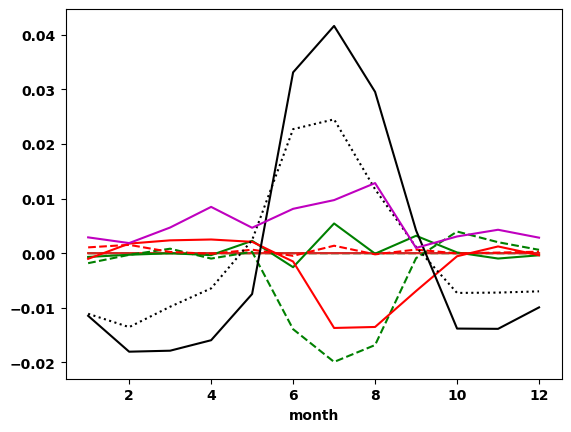

In [94]:
T_sen_AS.plot(linestyle='--')
T_driver_AS.plot(linestyle='-')

S_sen_AS.plot(linestyle='--')
S_driver_AS.plot(linestyle='-')

W_sen_AS.plot(linestyle='--',c='g')
W_driver_AS.plot(linestyle='-',c='g')

P_sen_AS.plot(linestyle='--',c='r')
P_driver_AS.plot(linestyle='-',c='r')

sea_flux_AS_1019.plot(linestyle=':',c='k')
sea_flux_AS_8089.plot(c='k')

res_AS.plot(c='m')

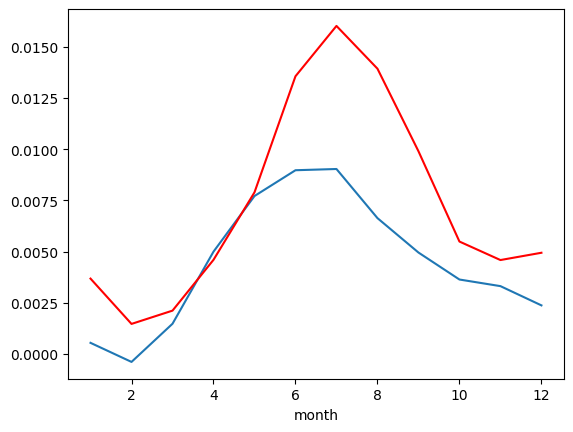

In [45]:
der_W_AS_1019.plot()
der_W_AS_8089.plot(c='r')

## WAS

In [46]:
pco2_WAS_1019 = pco2_1019.sel(LON=slice(30,65),LAT=slice(0,30)).mean(dim=['LAT','LON'])
pco2_atm_WAS_1019 = pco2_atm_1019.sel(LON=slice(30,65),LAT=slice(0,30)).mean(dim=['LAT','LON'])
temp_WAS_1019 = temp_1019.sel(LON=slice(30,65),LAT=slice(0,30)).mean(dim=['LAT','LON'])
sal_WAS_1019 = sal_1019.sel(LON=slice(30,65),LAT=slice(0,30)).mean(dim=['LAT','LON'])
ws_WAS_1019 = ws_1019.sel(LON=slice(30,65),LAT=slice(0,30)).mean(dim=['LAT','LON'])

flux_WAS_1019 = air_sea_CO2_flux(temp_WAS_1019, sal_WAS_1019, ws_WAS_1019, pco2_WAS_1019, pco2_atm_WAS_1019)*area_WAS*(12.0 / 1e15)
sea_flux_WAS_1019 = flux_WAS_1019 - flux_WAS_1019.mean()

temp_WAS_1019_dev = temp_WAS_1019 + 0.0001*temp_WAS_1019.mean()
flux_T_WAS_1019 = air_sea_CO2_flux(temp_WAS_1019_dev, sal_WAS_1019, ws_WAS_1019, pco2_WAS_1019, pco2_atm_WAS_1019)*area_WAS*(12.0 / 1e15)
T_WAS_1019 = ((flux_T_WAS_1019-flux_WAS_1019)/(0.0001*temp_WAS_1019))*(temp_WAS_1019 - temp_WAS_1019.mean())

sal_WAS_1019_dev = sal_WAS_1019 + 0.0001*sal_WAS_1019.mean()
flux_S_WAS_1019 = air_sea_CO2_flux(temp_WAS_1019, sal_WAS_1019_dev, ws_WAS_1019, pco2_WAS_1019, pco2_atm_WAS_1019)*area_WAS*(12.0 / 1e15)
S_WAS_1019 = ((flux_S_WAS_1019-flux_WAS_1019)/(0.0001*sal_WAS_1019.mean()))*(sal_WAS_1019 - sal_WAS_1019.mean())

ws_WAS_1019_dev = ws_WAS_1019 + 0.0001*ws_WAS_1019.mean()
flux_WS_WAS_1019 = air_sea_CO2_flux(temp_WAS_1019, sal_WAS_1019, ws_WAS_1019_dev, pco2_WAS_1019, pco2_atm_WAS_1019)*area_WAS*(12.0 / 1e15)
W_WAS_1019 = ((flux_WS_WAS_1019-flux_WAS_1019)/(0.0001*ws_WAS_1019.mean()))*(ws_WAS_1019 - ws_WAS_1019.mean())

pco2_WAS_1019_dev = pco2_WAS_1019 + 0.0001*pco2_WAS_1019.mean()
pco2_atm_WAS_1019_dev = pco2_atm_WAS_1019 + 0.0001*pco2_atm_WAS_1019.mean()
flux_P_WAS_1019 = air_sea_CO2_flux(temp_WAS_1019, sal_WAS_1019, ws_WAS_1019, pco2_WAS_1019_dev, pco2_atm_WAS_1019_dev)*area_WAS*(12.0 / 1e15)
P_WAS_1019 = ((flux_P_WAS_1019-flux_WAS_1019)/(0.0001*(pco2_WAS_1019-pco2_atm_WAS_1019).mean()))*((pco2_WAS_1019-pco2_WAS_1019.mean()) - (pco2_atm_WAS_1019-pco2_atm_WAS_1019.mean()))

In [47]:
W_imp_WAS_1019 = W_WAS_1019.max() - W_WAS_1019.min()
P_imp_WAS_1019 = P_WAS_1019.max() - P_WAS_1019.min()
T_imp_WAS_1019 = T_WAS_1019.max() - T_WAS_1019.min()
S_imp_WAS_1019 = S_WAS_1019.max() - S_WAS_1019.min()

print(f"Wind_imp_WAS: {W_imp_WAS_1019:.2f} PgC yr⁻¹")
print(f"pco2_imp_WAS: {P_imp_WAS_1019:.2f} PgC yr⁻¹")
print(f"temp_imp_WAS: {T_imp_WAS_1019:.2f} PgC yr⁻¹")
print(f"sal_imp_WAS: {S_imp_WAS_1019:.2f} PgC yr⁻¹")

Wind_imp_WAS: 0.03 PgC yr⁻¹
pco2_imp_WAS: 0.01 PgC yr⁻¹
temp_imp_WAS: 0.00 PgC yr⁻¹
sal_imp_WAS: 0.00 PgC yr⁻¹


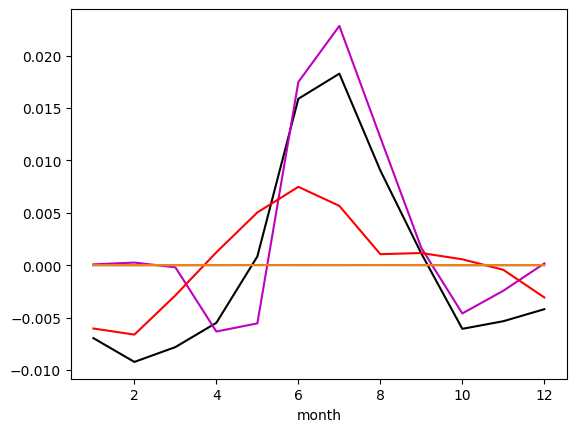

In [48]:
sea_flux_WAS_1019.plot(c='k')
W_WAS_1019.plot(c='m')
P_WAS_1019.plot(c='r')
T_WAS_1019.plot()
S_WAS_1019.plot()

## EAS

In [49]:
pco2_EAS_1019 = pco2_1019.sel(LON=slice(65,78),LAT=slice(0,30)).mean(dim=['LAT','LON'])
pco2_atm_EAS_1019 = pco2_atm_1019.sel(LON=slice(65,78),LAT=slice(0,30)).mean(dim=['LAT','LON'])
temp_EAS_1019 = temp_1019.sel(LON=slice(65,78),LAT=slice(0,30)).mean(dim=['LAT','LON'])
sal_EAS_1019 = sal_1019.sel(LON=slice(65,78),LAT=slice(0,30)).mean(dim=['LAT','LON'])
ws_EAS_1019 = ws_1019.sel(LON=slice(65,78),LAT=slice(0,30)).mean(dim=['LAT','LON'])

flux_EAS_1019 = air_sea_CO2_flux(temp_EAS_1019, sal_EAS_1019, ws_EAS_1019, pco2_EAS_1019, pco2_atm_EAS_1019)*area_EAS*(12.0 / 1e15)
sea_flux_EAS_1019 = flux_EAS_1019 - flux_EAS_1019.mean()

temp_EAS_1019_dev = temp_EAS_1019 + 0.0001*temp_EAS_1019.mean()
flux_T_EAS_1019 = air_sea_CO2_flux(temp_EAS_1019_dev, sal_EAS_1019, ws_EAS_1019, pco2_EAS_1019, pco2_atm_EAS_1019)*area_EAS*(12.0 / 1e15)
T_EAS_1019 = ((flux_T_EAS_1019-flux_EAS_1019)/(0.0001*temp_EAS_1019))*(temp_EAS_1019 - temp_EAS_1019.mean())

sal_EAS_1019_dev = sal_EAS_1019 + 0.0001*sal_EAS_1019.mean()
flux_S_EAS_1019 = air_sea_CO2_flux(temp_EAS_1019, sal_EAS_1019_dev, ws_EAS_1019, pco2_EAS_1019, pco2_atm_EAS_1019)*area_EAS*(12.0 / 1e15)
S_EAS_1019 = ((flux_S_EAS_1019-flux_EAS_1019)/(0.0001*sal_EAS_1019.mean()))*(sal_EAS_1019 - sal_EAS_1019.mean())

ws_EAS_1019_dev = ws_EAS_1019 + 0.0001*ws_EAS_1019.mean()
flux_WS_EAS_1019 = air_sea_CO2_flux(temp_EAS_1019, sal_EAS_1019, ws_EAS_1019_dev, pco2_EAS_1019, pco2_atm_EAS_1019)*area_EAS*(12.0 / 1e15)
W_EAS_1019 = ((flux_WS_EAS_1019-flux_EAS_1019)/(0.0001*ws_EAS_1019.mean()))*(ws_EAS_1019 - ws_EAS_1019.mean())

pco2_EAS_1019_dev = pco2_EAS_1019 + 0.0001*pco2_EAS_1019.mean()
pco2_atm_EAS_1019_dev = pco2_atm_EAS_1019 + 0.0001*pco2_atm_EAS_1019.mean()
flux_P_EAS_1019 = air_sea_CO2_flux(temp_EAS_1019, sal_EAS_1019, ws_EAS_1019, pco2_EAS_1019_dev, pco2_atm_EAS_1019_dev)*area_EAS*(12.0 / 1e15)
P_EAS_1019 = ((flux_P_EAS_1019-flux_EAS_1019)/(0.0001*(pco2_EAS_1019-pco2_atm_EAS_1019).mean()))*((pco2_EAS_1019-pco2_EAS_1019.mean()) - (pco2_atm_EAS_1019-pco2_atm_EAS_1019.mean()))

In [50]:
W_imp_EAS_1019 = W_EAS_1019.max() - W_EAS_1019.min()
P_imp_EAS_1019 = P_EAS_1019.max() - P_EAS_1019.min()
T_imp_EAS_1019 = T_EAS_1019.max() - T_EAS_1019.min()
S_imp_EAS_1019 = S_EAS_1019.max() - S_EAS_1019.min()

print(f"Wind_imp_EAS: {W_imp_EAS_1019:.2f} PgC yr⁻¹")
print(f"pco2_imp_EAS: {P_imp_EAS_1019:.2f} PgC yr⁻¹")
print(f"temp_imp_EAS: {T_imp_EAS_1019:.2f} PgC yr⁻¹")
print(f"sal_imp_EAS: {S_imp_EAS_1019:.2f} PgC yr⁻¹")

Wind_imp_EAS: 0.02 PgC yr⁻¹
pco2_imp_EAS: 0.01 PgC yr⁻¹
temp_imp_EAS: 0.00 PgC yr⁻¹
sal_imp_EAS: 0.00 PgC yr⁻¹


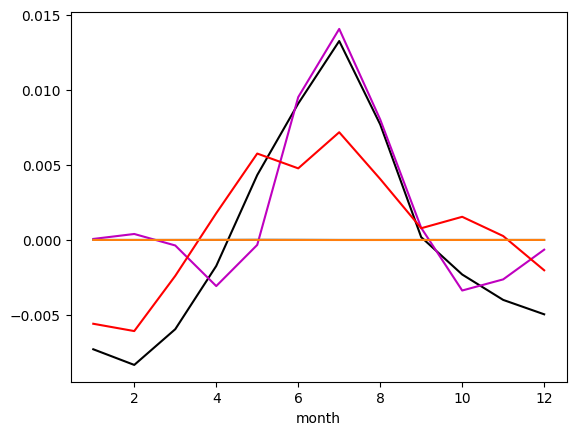

In [51]:
sea_flux_EAS_1019.plot(c='k')
W_EAS_1019.plot(c='m')
P_EAS_1019.plot(c='r')
T_EAS_1019.plot()
S_EAS_1019.plot()

## BoB

In [52]:
pco2_BoB_1019 = pco2_1019.sel(LON=slice(78,110),LAT=slice(0,30)).mean(dim=['LAT','LON'])
pco2_atm_BoB_1019 = pco2_atm_1019.sel(LON=slice(78,110),LAT=slice(0,30)).mean(dim=['LAT','LON'])
temp_BoB_1019 = temp_1019.sel(LON=slice(78,110),LAT=slice(0,30)).mean(dim=['LAT','LON'])
sal_BoB_1019 = sal_1019.sel(LON=slice(78,110),LAT=slice(0,30)).mean(dim=['LAT','LON'])
ws_BoB_1019 = ws_1019.sel(LON=slice(78,110),LAT=slice(0,30)).mean(dim=['LAT','LON'])

flux_BoB_1019 = air_sea_CO2_flux(temp_BoB_1019, sal_BoB_1019, ws_BoB_1019, pco2_BoB_1019, pco2_atm_BoB_1019)*area_BoB*(12.0 / 1e15)
sea_flux_BoB_1019 = flux_BoB_1019 - flux_BoB_1019.mean()

temp_BoB_1019_dev = temp_BoB_1019 + 0.0001*temp_BoB_1019.mean()
flux_T_BoB_1019 = air_sea_CO2_flux(temp_BoB_1019_dev, sal_BoB_1019, ws_BoB_1019, pco2_BoB_1019, pco2_atm_BoB_1019)*area_BoB*(12.0 / 1e15)
der_T_BoB_1019 = ((flux_T_BoB_1019-flux_BoB_1019)/(0.0001*temp_BoB_1019))
anm_T_BoB_1019 = (temp_BoB_1019 - temp_BoB_1019.mean())
T_BoB_1019 = der_T_AS_1019*anm_T_AS_1019
# T_BoB_1019 = ((flux_T_BoB_1019-flux_BoB_1019)/(0.0001*temp_BoB_1019))*(temp_BoB_1019 - temp_BoB_1019.mean())

sal_BoB_1019_dev = sal_BoB_1019 + 0.0001*sal_BoB_1019.mean()
flux_S_BoB_1019 = air_sea_CO2_flux(temp_BoB_1019, sal_BoB_1019_dev, ws_BoB_1019, pco2_BoB_1019, pco2_atm_BoB_1019)*area_BoB*(12.0 / 1e15)
der_S_BoB_1019 = ((flux_S_BoB_1019-flux_BoB_1019)/(0.0001*sal_BoB_1019.mean()))
anm_S_BoB_1019 = (sal_BoB_1019 - sal_BoB_1019.mean())
S_BoB_1019 = der_S_AS_1019*anm_S_AS_1019
# S_BoB_1019 = ((flux_S_BoB_1019-flux_BoB_1019)/(0.0001*sal_BoB_1019.mean()))*(sal_BoB_1019 - sal_BoB_1019.mean())

ws_BoB_1019_dev = ws_BoB_1019 + 0.0001*ws_BoB_1019.mean()
flux_WS_BoB_1019 = air_sea_CO2_flux(temp_BoB_1019, sal_BoB_1019, ws_BoB_1019_dev, pco2_BoB_1019, pco2_atm_BoB_1019)*area_BoB*(12.0 / 1e15)
der_W_BoB_1019 = ((flux_WS_BoB_1019-flux_BoB_1019)/(0.0001*ws_BoB_1019.mean()))
anm_W_BoB_1019 = (ws_BoB_1019 - ws_BoB_1019.mean())
W_BoB_1019 = der_W_BoB_1019*anm_W_BoB_1019
# W_BoB_1019 = ((flux_WS_BoB_1019-flux_BoB_1019)/(0.0001*ws_BoB_1019.mean()))*(ws_BoB_1019 - ws_BoB_1019.mean())

pco2_BoB_1019_dev = pco2_BoB_1019 + 0.0001*pco2_BoB_1019.mean()
pco2_atm_BoB_1019_dev = pco2_atm_BoB_1019 + 0.0001*pco2_atm_BoB_1019.mean()
flux_P_BoB_1019 = air_sea_CO2_flux(temp_BoB_1019, sal_BoB_1019, ws_BoB_1019, pco2_BoB_1019_dev, pco2_atm_BoB_1019_dev)*area_BoB*(12.0 / 1e15)
der_P_BoB_1019 = ((flux_P_BoB_1019-flux_BoB_1019)/(0.0001*(pco2_BoB_1019-pco2_atm_BoB_1019).mean()))
anm_P_BoB_1019 = ((pco2_BoB_1019-pco2_BoB_1019.mean()) - (pco2_atm_BoB_1019-pco2_atm_BoB_1019.mean()))
P_BoB_1019 = der_P_BoB_1019*anm_P_BoB_1019
# P_BoB_1019 = ((flux_P_BoB_1019-flux_BoB_1019)/(0.0001*(pco2_BoB_1019-pco2_atm_BoB_1019).mean()))*((pco2_BoB_1019-pco2_BoB_1019.mean()) - (pco2_atm_BoB_1019-pco2_atm_BoB_1019.mean()))

In [53]:
W_imp_BoB_1019 = W_BoB_1019.max() - W_BoB_1019.min()
P_imp_BoB_1019 = P_BoB_1019.max() - P_BoB_1019.min()
T_imp_BoB_1019 = T_BoB_1019.max() - T_BoB_1019.min()
S_imp_BoB_1019 = S_BoB_1019.max() - S_BoB_1019.min()

print(f"Wind_imp_BoB: {W_imp_BoB_1019:.2f} PgC yr⁻¹")
print(f"pco2_imp_BoB: {P_imp_BoB_1019:.2f} PgC yr⁻¹")
print(f"temp_imp_BoB: {T_imp_BoB_1019:.2f} PgC yr⁻¹")
print(f"sal_imp_BoB: {S_imp_BoB_1019:.2f} PgC yr⁻¹")

Wind_imp_BoB: 0.02 PgC yr⁻¹
pco2_imp_BoB: 0.02 PgC yr⁻¹
temp_imp_BoB: 0.00 PgC yr⁻¹
sal_imp_BoB: 0.00 PgC yr⁻¹


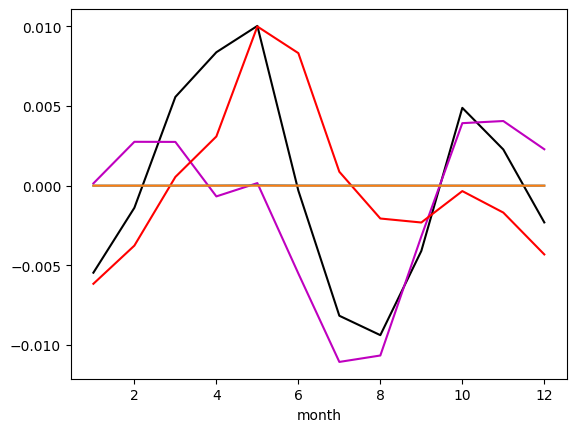

In [54]:
sea_flux_BoB_1019.plot(c='k')
W_BoB_1019.plot(c='m')
P_BoB_1019.plot(c='r')
T_BoB_1019.plot()
S_BoB_1019.plot()

In [55]:
T_sen_BoB = (anm_T_BoB_8089*(der_T_BoB_1019-der_T_BoB_8089))
T_driver_BoB = ((anm_T_BoB_1019-anm_T_BoB_8089)*der_T_BoB_8089)

S_sen_BoB = (anm_S_BoB_8089*(der_S_BoB_1019-der_S_BoB_8089))
S_driver_BoB = ((anm_S_BoB_1019-anm_S_BoB_8089)*der_S_BoB_8089)

W_sen_BoB = (anm_W_BoB_8089*(der_W_BoB_1019-der_W_BoB_8089))
W_driver_BoB = ((anm_W_BoB_1019-anm_W_BoB_8089)*der_W_BoB_8089)

P_sen_BoB = (anm_P_BoB_8089*(der_P_BoB_1019-der_P_BoB_8089))
P_driver_BoB = ((anm_P_BoB_1019-anm_P_BoB_8089)*der_P_BoB_8089)

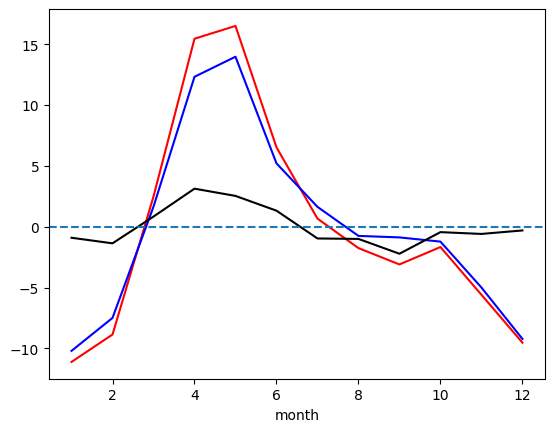

In [56]:
anm_P_BoB_1019.plot(c='r')
anm_P_BoB_8089.plot(c='b')
(anm_P_BoB_1019-anm_P_BoB_8089).plot(c='k')
plt.axhline(y=0,linestyle='--')

In [95]:
res_BoB = (sea_flux_BoB_1019-sea_flux_BoB_8089) - (T_sen_BoB+T_driver_BoB+S_sen_BoB+S_driver_BoB+W_sen_BoB+W_driver_BoB+P_sen_BoB+P_driver_BoB)

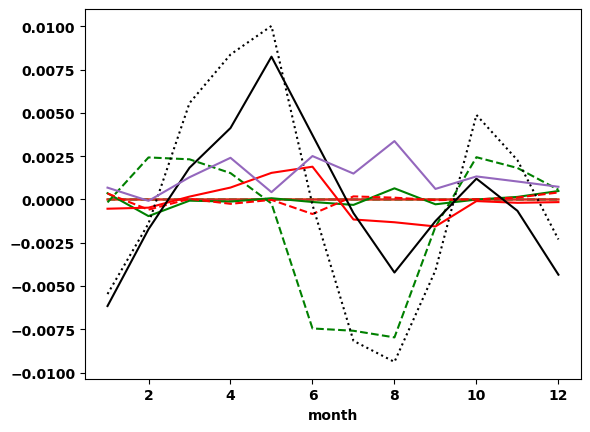

In [96]:
T_sen_BoB.plot(linestyle='--')
T_driver_BoB.plot(linestyle='-')

S_sen_BoB.plot(linestyle='--')
S_driver_BoB.plot(linestyle='-')

W_sen_BoB.plot(linestyle='--',c='g')
W_driver_BoB.plot(linestyle='-',c='g')

P_sen_BoB.plot(linestyle='--',c='r')
P_driver_BoB.plot(linestyle='-',c='r')

sea_flux_BoB_1019.plot(linestyle=':',c='k')
sea_flux_BoB_8089.plot(c='k')

res_BoB.plot()

## NBoB

In [58]:
pco2_NBoB_1019 = pco2_1019.sel(LON=slice(78,110),LAT=slice(15,30)).mean(dim=['LAT','LON'])
pco2_atm_NBoB_1019 = pco2_atm_1019.sel(LON=slice(78,110),LAT=slice(15,30)).mean(dim=['LAT','LON'])
temp_NBoB_1019 = temp_1019.sel(LON=slice(78,110),LAT=slice(15,30)).mean(dim=['LAT','LON'])
sal_NBoB_1019 = sal_1019.sel(LON=slice(78,110),LAT=slice(15,30)).mean(dim=['LAT','LON'])
ws_NBoB_1019 = ws_1019.sel(LON=slice(78,110),LAT=slice(15,30)).mean(dim=['LAT','LON'])

flux_NBoB_1019 = air_sea_CO2_flux(temp_NBoB_1019, sal_NBoB_1019, ws_NBoB_1019, pco2_NBoB_1019, pco2_atm_NBoB_1019)*area_NBoB*(12.0 / 1e15)
sea_flux_NBoB_1019 = flux_NBoB_1019 - flux_NBoB_1019.mean()

temp_NBoB_1019_dev = temp_NBoB_1019 + 0.0001*temp_NBoB_1019.mean()
flux_T_NBoB_1019 = air_sea_CO2_flux(temp_NBoB_1019_dev, sal_NBoB_1019, ws_NBoB_1019, pco2_NBoB_1019, pco2_atm_NBoB_1019)*area_NBoB*(12.0 / 1e15)
T_NBoB_1019 = ((flux_T_NBoB_1019-flux_NBoB_1019)/(0.0001*temp_NBoB_1019))*(temp_NBoB_1019 - temp_NBoB_1019.mean())

sal_NBoB_1019_dev = sal_NBoB_1019 + 0.0001*sal_NBoB_1019.mean()
flux_S_NBoB_1019 = air_sea_CO2_flux(temp_NBoB_1019, sal_NBoB_1019_dev, ws_NBoB_1019, pco2_NBoB_1019, pco2_atm_NBoB_1019)*area_NBoB*(12.0 / 1e15)
S_NBoB_1019 = ((flux_S_NBoB_1019-flux_NBoB_1019)/(0.0001*sal_NBoB_1019.mean()))*(sal_NBoB_1019 - sal_NBoB_1019.mean())

ws_NBoB_1019_dev = ws_NBoB_1019 + 0.0001*ws_NBoB_1019.mean()
flux_WS_NBoB_1019 = air_sea_CO2_flux(temp_NBoB_1019, sal_NBoB_1019, ws_NBoB_1019_dev, pco2_NBoB_1019, pco2_atm_NBoB_1019)*area_NBoB*(12.0 / 1e15)
W_NBoB_1019 = ((flux_WS_NBoB_1019-flux_NBoB_1019)/(0.0001*ws_NBoB_1019.mean()))*(ws_NBoB_1019 - ws_NBoB_1019.mean())

pco2_NBoB_1019_dev = pco2_NBoB_1019 + 0.0001*pco2_NBoB_1019.mean()
pco2_atm_NBoB_1019_dev = pco2_atm_NBoB_1019 + 0.0001*pco2_atm_NBoB_1019.mean()
flux_P_NBoB_1019 = air_sea_CO2_flux(temp_NBoB_1019, sal_NBoB_1019, ws_NBoB_1019, pco2_NBoB_1019_dev, pco2_atm_NBoB_1019_dev)*area_NBoB*(12.0 / 1e15)
P_NBoB_1019 = ((flux_P_NBoB_1019-flux_NBoB_1019)/(0.0001*(pco2_NBoB_1019-pco2_atm_NBoB_1019).mean()))*((pco2_NBoB_1019-pco2_NBoB_1019.mean()) - (pco2_atm_NBoB_1019-pco2_atm_NBoB_1019.mean()))

In [59]:
W_imp_NBoB_1019 = W_NBoB_1019.max() - W_NBoB_1019.min()
P_imp_NBoB_1019 = P_NBoB_1019.max() - P_NBoB_1019.min()
T_imp_NBoB_1019 = T_NBoB_1019.max() - T_NBoB_1019.min()
S_imp_NBoB_1019 = S_NBoB_1019.max() - S_NBoB_1019.min()

print(f"Wind_imp_NBoB: {W_imp_NBoB_1019:.2f} PgC yr⁻¹")
print(f"pco2_imp_NBoB: {P_imp_NBoB_1019:.2f} PgC yr⁻¹")
print(f"temp_imp_NBoB: {T_imp_NBoB_1019:.2f} PgC yr⁻¹")
print(f"sal_imp_NBoB: {S_imp_NBoB_1019:.2f} PgC yr⁻¹")

Wind_imp_NBoB: 0.01 PgC yr⁻¹
pco2_imp_NBoB: 0.01 PgC yr⁻¹
temp_imp_NBoB: 0.00 PgC yr⁻¹
sal_imp_NBoB: 0.00 PgC yr⁻¹


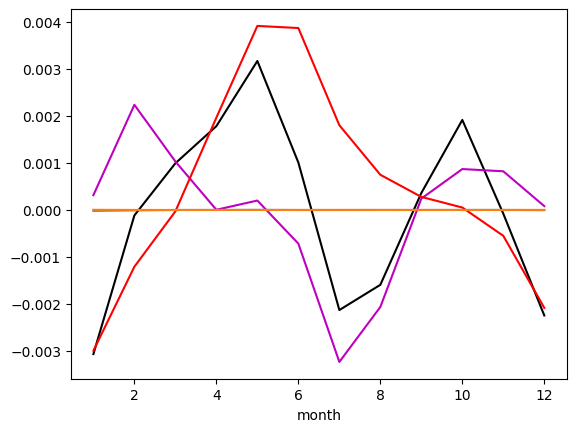

In [60]:
sea_flux_NBoB_1019.plot(c='k')
W_NBoB_1019.plot(c='m')
P_NBoB_1019.plot(c='r')
T_NBoB_1019.plot()
S_NBoB_1019.plot()

## SBoB

In [61]:
pco2_SBoB_1019 = pco2_1019.sel(LON=slice(78,110),LAT=slice(0,15)).mean(dim=['LAT','LON'])
pco2_atm_SBoB_1019 = pco2_atm_1019.sel(LON=slice(78,110),LAT=slice(0,15)).mean(dim=['LAT','LON'])
temp_SBoB_1019 = temp_1019.sel(LON=slice(78,110),LAT=slice(0,15)).mean(dim=['LAT','LON'])
sal_SBoB_1019 = sal_1019.sel(LON=slice(78,110),LAT=slice(0,15)).mean(dim=['LAT','LON'])
ws_SBoB_1019 = ws_1019.sel(LON=slice(78,110),LAT=slice(0,15)).mean(dim=['LAT','LON'])

flux_SBoB_1019 = air_sea_CO2_flux(temp_SBoB_1019, sal_SBoB_1019, ws_SBoB_1019, pco2_SBoB_1019, pco2_atm_SBoB_1019)*area_SBoB*(12.0 / 1e15)
sea_flux_SBoB_1019 = flux_SBoB_1019 - flux_SBoB_1019.mean()

temp_SBoB_1019_dev = temp_SBoB_1019 + 0.0001*temp_SBoB_1019.mean()
flux_T_SBoB_1019 = air_sea_CO2_flux(temp_SBoB_1019_dev, sal_SBoB_1019, ws_SBoB_1019, pco2_SBoB_1019, pco2_atm_SBoB_1019)*area_SBoB*(12.0 / 1e15)
T_SBoB_1019 = ((flux_T_SBoB_1019-flux_SBoB_1019)/(0.0001*temp_SBoB_1019))*(temp_SBoB_1019 - temp_SBoB_1019.mean())

sal_SBoB_1019_dev = sal_SBoB_1019 + 0.0001*sal_SBoB_1019.mean()
flux_S_SBoB_1019 = air_sea_CO2_flux(temp_SBoB_1019, sal_SBoB_1019_dev, ws_SBoB_1019, pco2_SBoB_1019, pco2_atm_SBoB_1019)*area_SBoB*(12.0 / 1e15)
S_SBoB_1019 = ((flux_S_SBoB_1019-flux_SBoB_1019)/(0.0001*sal_SBoB_1019.mean()))*(sal_SBoB_1019 - sal_SBoB_1019.mean())

ws_SBoB_1019_dev = ws_SBoB_1019 + 0.0001*ws_SBoB_1019.mean()
flux_WS_SBoB_1019 = air_sea_CO2_flux(temp_SBoB_1019, sal_SBoB_1019, ws_SBoB_1019_dev, pco2_SBoB_1019, pco2_atm_SBoB_1019)*area_SBoB*(12.0 / 1e15)
W_SBoB_1019 = ((flux_WS_SBoB_1019-flux_SBoB_1019)/(0.0001*ws_SBoB_1019.mean()))*(ws_SBoB_1019 - ws_SBoB_1019.mean())

pco2_SBoB_1019_dev = pco2_SBoB_1019 + 0.0001*pco2_SBoB_1019.mean()
pco2_atm_SBoB_1019_dev = pco2_atm_SBoB_1019 + 0.0001*pco2_atm_SBoB_1019.mean()
flux_P_SBoB_1019 = air_sea_CO2_flux(temp_SBoB_1019, sal_SBoB_1019, ws_SBoB_1019, pco2_SBoB_1019_dev, pco2_atm_SBoB_1019_dev)*area_SBoB*(12.0 / 1e15)
P_SBoB_1019 = ((flux_P_SBoB_1019-flux_SBoB_1019)/(0.0001*(pco2_SBoB_1019-pco2_atm_SBoB_1019).mean()))*((pco2_SBoB_1019-pco2_SBoB_1019.mean()) - (pco2_atm_SBoB_1019-pco2_atm_SBoB_1019.mean()))

In [62]:
W_imp_SBoB_1019 = W_SBoB_1019.max() - W_SBoB_1019.min()
P_imp_SBoB_1019 = P_SBoB_1019.max() - P_SBoB_1019.min()
T_imp_SBoB_1019 = T_SBoB_1019.max() - T_SBoB_1019.min()
S_imp_SBoB_1019 = S_SBoB_1019.max() - S_SBoB_1019.min()

print(f"Wind_imp_SBoB: {W_imp_SBoB_1019:.2f} PgC yr⁻¹")
print(f"pco2_imp_SBoB: {P_imp_SBoB_1019:.2f} PgC yr⁻¹")
print(f"temp_imp_SBoB: {T_imp_SBoB_1019:.2f} PgC yr⁻¹")
print(f"sal_imp_SBoB: {S_imp_SBoB_1019:.2f} PgC yr⁻¹")

Wind_imp_SBoB: 0.01 PgC yr⁻¹
pco2_imp_SBoB: 0.01 PgC yr⁻¹
temp_imp_SBoB: 0.00 PgC yr⁻¹
sal_imp_SBoB: 0.00 PgC yr⁻¹


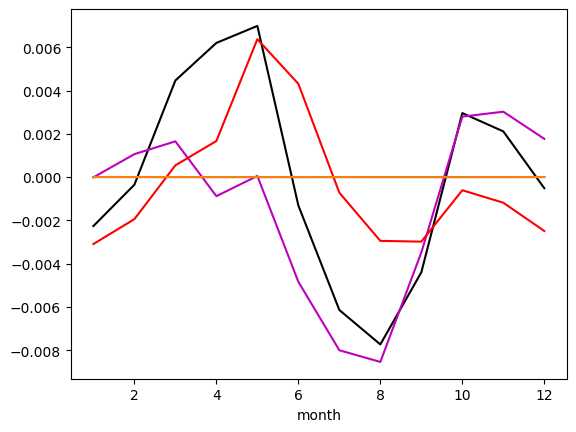

In [63]:
sea_flux_SBoB_1019.plot(c='k')
W_SBoB_1019.plot(c='m')
P_SBoB_1019.plot(c='r')
T_SBoB_1019.plot()
S_SBoB_1019.plot()

## EIO

In [64]:
pco2_EIO_1019 = pco2_1019.sel(LON=slice(30,120),LAT=slice(-18,0)).mean(dim=['LAT','LON'])
pco2_atm_EIO_1019 = pco2_atm_1019.sel(LON=slice(30,120),LAT=slice(-18,0)).mean(dim=['LAT','LON'])
temp_EIO_1019 = temp_1019.sel(LON=slice(30,120),LAT=slice(-18,0)).mean(dim=['LAT','LON'])
sal_EIO_1019 = sal_1019.sel(LON=slice(30,120),LAT=slice(-18,0)).mean(dim=['LAT','LON'])
ws_EIO_1019 = ws_1019.sel(LON=slice(30,120),LAT=slice(-18,0)).mean(dim=['LAT','LON'])

flux_EIO_1019 = air_sea_CO2_flux(temp_EIO_1019, sal_EIO_1019, ws_EIO_1019, pco2_EIO_1019, pco2_atm_EIO_1019)*area_EIO*(12.0 / 1e15)
sea_flux_EIO_1019 = flux_EIO_1019 - flux_EIO_1019.mean()

temp_EIO_1019_dev = temp_EIO_1019 + 0.0001*temp_EIO_1019.mean()
flux_T_EIO_1019 = air_sea_CO2_flux(temp_EIO_1019_dev, sal_EIO_1019, ws_EIO_1019, pco2_EIO_1019, pco2_atm_EIO_1019)*area_EIO*(12.0 / 1e15)
der_T_EIO_1019 = ((flux_T_EIO_1019-flux_EIO_1019)/(0.0001*temp_EIO_1019.mean()))
anm_T_EIO_1019 = (temp_EIO_1019 - temp_EIO_1019.mean())
T_EIO_1019 = der_T_EIO_1019*anm_T_EIO_1019

sal_EIO_1019_dev = sal_EIO_1019 + 0.0001*sal_EIO_1019.mean()
flux_S_EIO_1019 = air_sea_CO2_flux(temp_EIO_1019, sal_EIO_1019_dev, ws_EIO_1019, pco2_EIO_1019, pco2_atm_EIO_1019)*area_EIO*(12.0 / 1e15)
der_S_EIO_1019 = ((flux_S_EIO_1019-flux_EIO_1019)/(0.0001*sal_EIO_1019.mean()))
anm_S_EIO_1019 = (sal_EIO_1019 - sal_EIO_1019.mean())
S_EIO_1019 = ((flux_S_EIO_1019-flux_EIO_1019)/(0.0001*sal_EIO_1019.mean()))*(sal_EIO_1019 - sal_EIO_1019.mean())

ws_EIO_1019_dev = ws_EIO_1019 + 0.0001*ws_EIO_1019.mean()
flux_WS_EIO_1019 = air_sea_CO2_flux(temp_EIO_1019, sal_EIO_1019, ws_EIO_1019_dev, pco2_EIO_1019, pco2_atm_EIO_1019)*area_EIO*(12.0 / 1e15)
der_W_EIO_1019 = ((flux_WS_EIO_1019-flux_EIO_1019)/(0.0001*ws_EIO_1019.mean()))
anm_W_EIO_1019 = (ws_EIO_1019 - ws_EIO_1019.mean())
W_EIO_1019 = der_W_EIO_1019*anm_W_EIO_1019

pco2_EIO_1019_dev = pco2_EIO_1019 + 0.0001*pco2_EIO_1019.mean()
pco2_atm_EIO_1019_dev = pco2_atm_EIO_1019 + 0.0001*pco2_atm_EIO_1019.mean()
flux_P_EIO_1019 = air_sea_CO2_flux(temp_EIO_1019, sal_EIO_1019, ws_EIO_1019, pco2_EIO_1019_dev, pco2_atm_EIO_1019_dev)*area_EIO*(12.0 / 1e15)
der_P_EIO_1019 = ((flux_P_EIO_1019-flux_EIO_1019)/(0.0001*(pco2_EIO_1019-pco2_atm_EIO_1019).mean()))
anm_P_EIO_1019 = ((pco2_EIO_1019-pco2_EIO_1019.mean()) - (pco2_atm_EIO_1019-pco2_atm_EIO_1019.mean()))
P_EIO_1019 = der_P_EIO_1019*anm_P_EIO_1019

In [65]:
W_imp_EIO_1019 = W_EIO_1019.max() - W_EIO_1019.min()
P_imp_EIO_1019 = P_EIO_1019.max() - P_EIO_1019.min()
T_imp_EIO_1019 = T_EIO_1019.max() - T_EIO_1019.min()
S_imp_EIO_1019 = S_EIO_1019.max() - S_EIO_1019.min()

print(f"Wind_imp_EIO: {W_imp_EIO_1019:.2f} PgC yr⁻¹")
print(f"pco2_imp_EIO: {P_imp_EIO_1019:.2f} PgC yr⁻¹")
print(f"temp_imp_EIO: {T_imp_EIO_1019:.2f} PgC yr⁻¹")
print(f"sal_imp_EIO: {S_imp_EIO_1019:.2f} PgC yr⁻¹")

Wind_imp_EIO: 0.06 PgC yr⁻¹
pco2_imp_EIO: 0.09 PgC yr⁻¹
temp_imp_EIO: 0.00 PgC yr⁻¹
sal_imp_EIO: 0.00 PgC yr⁻¹


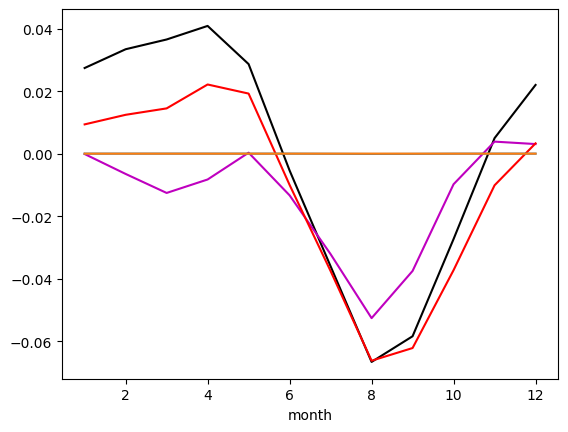

In [66]:
sea_flux_EIO_1019.plot(c='k')
W_EIO_1019.plot(c='m')
P_EIO_1019.plot(c='r')
T_EIO_1019.plot()
S_EIO_1019.plot()

In [67]:
T_sen_EIO = (anm_T_EIO_8089*(der_T_EIO_1019-der_T_EIO_8089))
T_driver_EIO = ((anm_T_EIO_1019-anm_T_EIO_8089)*der_T_EIO_8089)

S_sen_EIO = (anm_S_EIO_8089*(der_S_EIO_1019-der_S_EIO_8089))
S_driver_EIO = ((anm_S_EIO_1019-anm_S_EIO_8089)*der_S_EIO_8089)

W_sen_EIO = (anm_W_EIO_8089*(der_W_EIO_1019-der_W_EIO_8089))
W_driver_EIO = ((anm_W_EIO_1019-anm_W_EIO_8089)*der_W_EIO_8089)

P_sen_EIO = (anm_P_EIO_8089*(der_P_EIO_1019-der_P_EIO_8089))
P_driver_EIO = ((anm_P_EIO_1019-anm_P_EIO_8089)*der_P_EIO_8089)

In [97]:
res_EIO = (sea_flux_EIO_1019-sea_flux_EIO_8089) - (T_sen_EIO+T_driver_EIO+S_sen_EIO+S_driver_EIO+W_sen_EIO+W_driver_EIO+P_sen_EIO+P_driver_EIO)

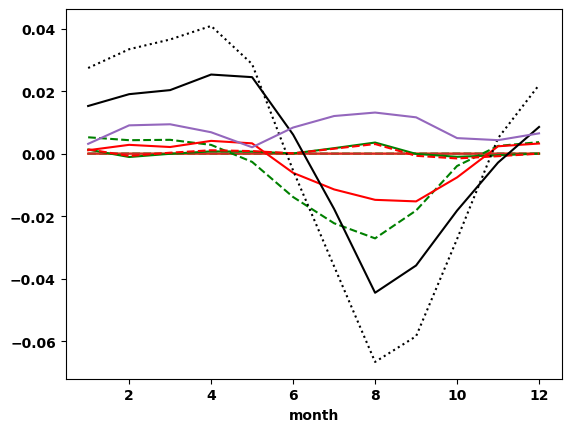

In [98]:
T_sen_EIO.plot(linestyle='--')
T_driver_EIO.plot(linestyle='-')

S_sen_EIO.plot(linestyle='--')
S_driver_EIO.plot(linestyle='-')

W_sen_EIO.plot(linestyle='--',c='g')
W_driver_EIO.plot(linestyle='-',c='g')

P_sen_EIO.plot(linestyle='--',c='r')
P_driver_EIO.plot(linestyle='-',c='r')

sea_flux_EIO_1019.plot(linestyle=':',c='k')
sea_flux_EIO_8089.plot(c='k')

res_EIO.plot()

## SIO

In [69]:
pco2_SIO_1019 = pco2_1019.sel(LON=slice(30,120),LAT=slice(-30,-18)).mean(dim=['LAT','LON'])
pco2_atm_SIO_1019 = pco2_atm_1019.sel(LON=slice(30,120),LAT=slice(-30,-18)).mean(dim=['LAT','LON'])
temp_SIO_1019 = temp_1019.sel(LON=slice(30,120),LAT=slice(-30,-18)).mean(dim=['LAT','LON'])
sal_SIO_1019 = sal_1019.sel(LON=slice(30,120),LAT=slice(-30,-18)).mean(dim=['LAT','LON'])
ws_SIO_1019 = ws_1019.sel(LON=slice(30,120),LAT=slice(-30,-18)).mean(dim=['LAT','LON'])

flux_SIO_1019 = air_sea_CO2_flux(temp_SIO_1019, sal_SIO_1019, ws_SIO_1019, pco2_SIO_1019, pco2_atm_SIO_1019)*area_SIO*(12.0 / 1e15)
sea_flux_SIO_1019 = flux_SIO_1019 - flux_SIO_1019.mean()

temp_SIO_1019_dev = temp_SIO_1019 + 0.0001*temp_SIO_1019.mean()
flux_T_SIO_1019 = air_sea_CO2_flux(temp_SIO_1019_dev, sal_SIO_1019, ws_SIO_1019, pco2_SIO_1019, pco2_atm_SIO_1019)*area_SIO*(12.0 / 1e15)
der_T_SIO_1019 = ((flux_T_SIO_1019-flux_SIO_1019)/(0.0001*temp_SIO_1019.mean()))
anm_T_SIO_1019 = (temp_SIO_1019 - temp_SIO_1019.mean())
T_SIO_1019 = der_T_SIO_1019*anm_T_SIO_1019

sal_SIO_1019_dev = sal_SIO_1019 + 0.0001*sal_SIO_1019.mean()
flux_S_SIO_1019 = air_sea_CO2_flux(temp_SIO_1019, sal_SIO_1019_dev, ws_SIO_1019, pco2_SIO_1019, pco2_atm_SIO_1019)*area_SIO*(12.0 / 1e15)
der_S_SIO_1019 = ((flux_S_SIO_1019-flux_SIO_1019)/(0.0001*sal_SIO_1019.mean()))
anm_S_SIO_1019 = (sal_SIO_1019 - sal_SIO_1019.mean())
S_SIO_1019 = der_S_SIO_1019*anm_S_SIO_1019

ws_SIO_1019_dev = ws_SIO_1019 + 0.0001*ws_SIO_1019.mean()
flux_WS_SIO_1019 = air_sea_CO2_flux(temp_SIO_1019, sal_SIO_1019, ws_SIO_1019_dev, pco2_SIO_1019, pco2_atm_SIO_1019)*area_SIO*(12.0 / 1e15)
der_W_SIO_1019 = ((flux_WS_SIO_1019-flux_SIO_1019)/(0.0001*ws_SIO_1019.mean()))
anm_W_SIO_1019 = (ws_SIO_1019 - ws_SIO_1019.mean())
W_SIO_1019 = der_W_SIO_1019*anm_W_SIO_1019

pco2_SIO_1019_dev = pco2_SIO_1019 + 0.0001*pco2_SIO_1019.mean()
pco2_atm_SIO_1019_dev = pco2_atm_SIO_1019 + 0.0001*pco2_atm_SIO_1019.mean()
flux_P_SIO_1019 = air_sea_CO2_flux(temp_SIO_1019, sal_SIO_1019, ws_SIO_1019, pco2_SIO_1019_dev, pco2_atm_SIO_1019_dev)*area_SIO*(12.0 / 1e15)
der_P_SIO_1019 =  ((flux_P_SIO_1019-flux_SIO_1019)/(0.0001*(pco2_SIO_1019-pco2_atm_SIO_1019).mean()))
anm_P_SIO_1019 = ((pco2_SIO_1019-pco2_SIO_1019.mean()) - (pco2_atm_SIO_1019-pco2_atm_SIO_1019.mean()))
P_SIO_1019 = der_P_SIO_1019*anm_P_SIO_1019

In [70]:
W_imp_SIO_1019 = W_SIO_1019.max() - W_SIO_1019.min()
P_imp_SIO_1019 = P_SIO_1019.max() - P_SIO_1019.min()
T_imp_SIO_1019 = T_SIO_1019.max() - T_SIO_1019.min()
S_imp_SIO_1019 = S_SIO_1019.max() - S_SIO_1019.min()

print(f"Wind_imp_SIO: {W_imp_SIO_1019:.2f} PgC yr⁻¹")
print(f"pco2_imp_SIO: {P_imp_SIO_1019:.2f} PgC yr⁻¹")
print(f"temp_imp_SIO: {T_imp_SIO_1019:.2f} PgC yr⁻¹")
print(f"sal_imp_SIO: {S_imp_SIO_1019:.2f} PgC yr⁻¹")

Wind_imp_SIO: 0.03 PgC yr⁻¹
pco2_imp_SIO: 0.09 PgC yr⁻¹
temp_imp_SIO: 0.00 PgC yr⁻¹
sal_imp_SIO: 0.00 PgC yr⁻¹


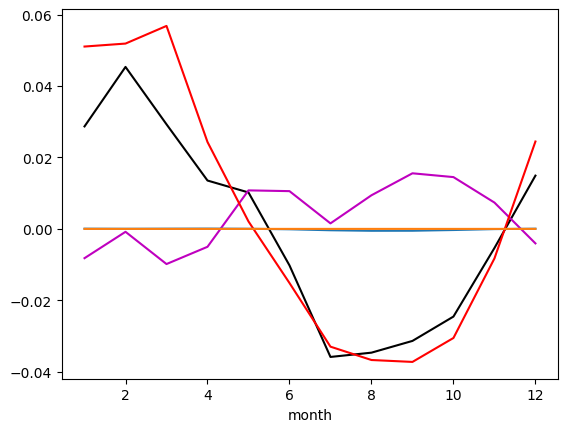

In [71]:
sea_flux_SIO_1019.plot(c='k')
W_SIO_1019.plot(c='m')
P_SIO_1019.plot(c='r')
T_SIO_1019.plot()
S_SIO_1019.plot()

In [72]:
T_sen_SIO = (anm_T_SIO_8089*(der_T_SIO_1019-der_T_SIO_8089))
T_driver_SIO = ((anm_T_SIO_1019-anm_T_SIO_8089)*der_T_SIO_8089)

S_sen_SIO = (anm_S_SIO_8089*(der_S_SIO_1019-der_S_SIO_8089))
S_driver_SIO = ((anm_S_SIO_1019-anm_S_SIO_8089)*der_S_SIO_8089)

W_sen_SIO = (anm_W_SIO_8089*(der_W_SIO_1019-der_W_SIO_8089))
W_driver_SIO = ((anm_W_SIO_1019-anm_W_SIO_8089)*der_W_SIO_8089)

P_sen_SIO = (anm_P_SIO_8089*(der_P_SIO_1019-der_P_SIO_8089))
P_driver_SIO = ((anm_P_SIO_1019-anm_P_SIO_8089)*der_P_SIO_8089)

In [99]:
res_SIO = (sea_flux_SIO_1019-sea_flux_SIO_8089) - (T_sen_SIO+T_driver_SIO+S_sen_SIO+S_driver_SIO+W_sen_SIO+W_driver_SIO+P_sen_SIO+P_driver_SIO)

## ESIO

In [73]:
# pco2_ESIO_1019 = pco2_1019.sel(LON=slice(75,120),LAT=slice(-30,-18)).mean(dim=['LAT','LON'])
# pco2_atm_ESIO_1019 = pco2_atm_1019.sel(LON=slice(75,120),LAT=slice(-30,-18)).mean(dim=['LAT','LON'])
# temp_ESIO_1019 = temp_1019.sel(LON=slice(75,120),LAT=slice(-30,-18)).mean(dim=['LAT','LON'])
# sal_ESIO_1019 = sal_1019.sel(LON=slice(75,120),LAT=slice(-30,-18)).mean(dim=['LAT','LON'])
# ws_ESIO_1019 = ws_1019.sel(LON=slice(75,120),LAT=slice(-30,-18)).mean(dim=['LAT','LON'])

# flux_ESIO_1019 = air_sea_CO2_flux(temp_ESIO_1019, sal_ESIO_1019, ws_ESIO_1019, pco2_ESIO_1019, pco2_atm_ESIO_1019)*area_ESIO*(12.0 / 1e15)
# sea_flux_ESIO_1019 = flux_ESIO_1019 - flux_ESIO_1019.mean()

# temp_ESIO_1019_dev = temp_ESIO_1019 + 0.0001*temp_ESIO_1019.mean()
# flux_T_ESIO_1019 = air_sea_CO2_flux(temp_ESIO_1019_dev, sal_ESIO_1019, ws_ESIO_1019, pco2_ESIO_1019, pco2_atm_ESIO_1019)*area_ESIO*(12.0 / 1e15)
# der_T_ESIO_1019 = ((flux_T_ESIO_1019-flux_ESIO_1019)/(0.0001*temp_ESIO_1019.mean()))
# anm_T_ESIO_1019 = (temp_ESIO_1019 - temp_ESIO_1019.mean())
# T_ESIO_1019 = der_T_ESIO_1019*anm_T_ESIO_1019

# sal_ESIO_1019_dev = sal_ESIO_1019 + 0.0001*sal_ESIO_1019.mean()
# flux_S_ESIO_1019 = air_sea_CO2_flux(temp_ESIO_1019, sal_ESIO_1019_dev, ws_ESIO_1019, pco2_ESIO_1019, pco2_atm_ESIO_1019)*area_ESIO*(12.0 / 1e15)
# der_S_ESIO_1019 = ((flux_S_ESIO_1019-flux_ESIO_1019)/(0.0001*sal_ESIO_1019.mean()))
# anm_S_ESIO_1019 = (sal_ESIO_1019 - sal_ESIO_1019.mean())
# S_ESIO_1019 = der_S_ESIO_1019*anm_S_ESIO_1019

# ws_ESIO_1019_dev = ws_ESIO_1019 + 0.0001*ws_ESIO_1019.mean()
# flux_WS_ESIO_1019 = air_sea_CO2_flux(temp_ESIO_1019, sal_ESIO_1019, ws_ESIO_1019_dev, pco2_ESIO_1019, pco2_atm_ESIO_1019)*area_ESIO*(12.0 / 1e15)
# der_W_ESIO_1019 = ((flux_WS_ESIO_1019-flux_ESIO_1019)/(0.0001*ws_ESIO_1019.mean()))
# anm_W_ESIO_1019 = (ws_ESIO_1019 - ws_ESIO_1019.mean())
# W_ESIO_1019 = der_W_ESIO_1019*anm_W_ESIO_1019

# pco2_ESIO_1019_dev = pco2_ESIO_1019 + 0.0001*pco2_ESIO_1019.mean()
# pco2_atm_ESIO_1019_dev = pco2_atm_ESIO_1019 + 0.0001*pco2_atm_ESIO_1019.mean()
# flux_P_ESIO_1019 = air_sea_CO2_flux(temp_ESIO_1019, sal_ESIO_1019, ws_ESIO_1019, pco2_ESIO_1019_dev, pco2_atm_ESIO_1019_dev)*area_ESIO*(12.0 / 1e15)
# der_P_ESIO_1019 =  ((flux_P_ESIO_1019-flux_ESIO_1019)/(0.0001*(pco2_ESIO_1019-pco2_atm_ESIO_1019).mean()))
# anm_P_ESIO_1019 = ((pco2_ESIO_1019-pco2_ESIO_1019.mean()) - (pco2_atm_ESIO_1019-pco2_atm_ESIO_1019.mean()))
# P_ESIO_1019 = der_P_ESIO_1019*anm_P_ESIO_1019

In [74]:
# W_imp_ESIO_1019 = W_ESIO_1019.max() - W_ESIO_1019.min()
# P_imp_ESIO_1019 = P_ESIO_1019.max() - P_ESIO_1019.min()
# T_imp_ESIO_1019 = T_ESIO_1019.max() - T_ESIO_1019.min()
# S_imp_ESIO_1019 = S_ESIO_1019.max() - S_ESIO_1019.min()

# print(f"Wind_imp_ESIO: {W_imp_ESIO_1019:.2f} PgC yr⁻¹")
# print(f"pco2_imp_ESIO: {P_imp_ESIO_1019:.2f} PgC yr⁻¹")
# print(f"temp_imp_ESIO: {T_imp_ESIO_1019:.2f} PgC yr⁻¹")
# print(f"sal_imp_ESIO: {S_imp_ESIO_1019:.2f} PgC yr⁻¹")

In [75]:
# sea_flux_ESIO_1019.plot(c='k')
# W_ESIO_1019.plot(c='m')
# P_ESIO_1019.plot(c='r')
# T_ESIO_1019.plot()
# S_ESIO_1019.plot()

In [76]:
# T_sen_ESIO = (anm_T_ESIO_1019*(der_T_ESIO_1019-der_T_ESIO_8089))
# T_driver_ESIO = ((anm_T_ESIO_1019-anm_T_ESIO_8089)*der_T_ESIO_8089)

# S_sen_ESIO = (anm_S_ESIO_1019*(der_S_ESIO_1019-der_S_ESIO_8089))
# S_driver_ESIO = ((anm_S_ESIO_1019-anm_S_ESIO_8089)*der_S_ESIO_8089)

# W_sen_ESIO = (anm_W_ESIO_1019*(der_W_ESIO_1019-der_W_ESIO_8089))
# W_driver_ESIO = ((anm_W_ESIO_1019-anm_W_ESIO_8089)*der_W_ESIO_8089)

# P_sen_ESIO = (anm_P_ESIO_1019*(der_P_ESIO_1019-der_P_ESIO_8089))
# P_driver_ESIO = ((anm_P_ESIO_1019-anm_P_ESIO_8089)*der_P_ESIO_8089)

In [77]:
# plt.rcParams["font.weight"]='bold'
# fig,ax = plt.subplots(1,1)

# ay = ax.twinx()
# T_sen_ESIO.plot(linestyle='--',ax=ax,label='SST_sen',linewidth=2,c='b')
# T_driver_ESIO.plot(linestyle='-',ax=ax,label='SST_driver',linewidth=2,c='b')

# S_sen_ESIO.plot(linestyle='--',ax=ax,label='SSS_sen',linewidth=2,c='m')
# S_driver_ESIO.plot(linestyle='-',ax=ax,label='SSS_driver',linewidth=2,c='m')

# W_sen_ESIO.plot(linestyle='--',c='g',ax=ax,label='WS_sen')
# W_driver_ESIO.plot(linestyle='-',c='g',ax=ax,label='WS_driver')

# P_sen_ESIO.plot(linestyle='--',c='r',ax=ax,label="$\mathbf{\Delta}$pCO$\mathbf{_2}$_sen")
# P_driver_ESIO.plot(linestyle='-',c='r',ax=ax,label="$\mathbf{\Delta}$pCO$\mathbf{_2}$_driver")

# ax.set_ylim([-0.02,0.02])

# sea_flux_ESIO_1019.plot(linestyle=':',c='k',ax=ay,label="$\mathbf{\delta}$CO$\mathbf{_2}$ flux (2010-2019)")
# sea_flux_ESIO_8089.plot(c='k',ax=ay,label="$\mathbf{\delta}$CO$\mathbf{_2}$ flux (1980-1989)")

# ay.set_ylim([-0.03,0.03])
# ax.legend(loc='best', bbox_to_anchor=(0.46, 0.75, 0.5, 0.5),ncols=3)
# ay.legend()
# ax.set_xlabel('Months',fontsize=18, fontweight="bold")
# ax.set_ylabel(r"$\mathbf{\Delta}\mathbf{\delta}$CO$\mathbf{_2}$ flux",fontsize=18, fontweight="bold")
# ay.set_ylabel(r"$\mathbf{\delta}$CO$\mathbf{_2}$ flux",fontsize=18, fontweight="bold")

In [ ]:
BoB

Text(0, 0.5, '$\\mathbf{\\delta}$CO$\\mathbf{_2}$ flux')

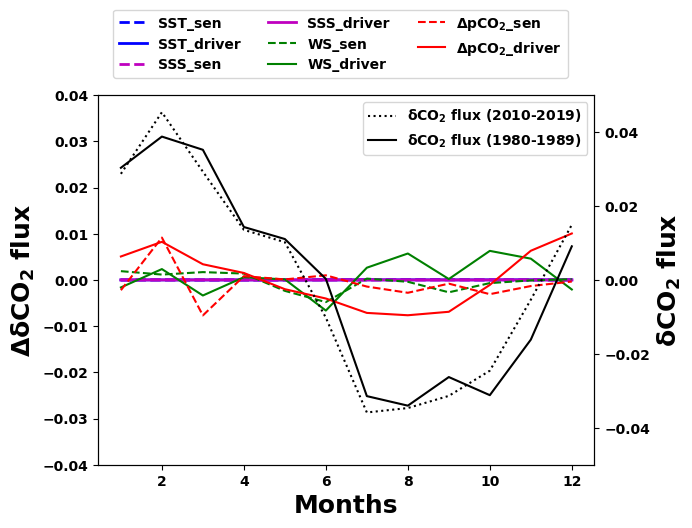

In [78]:
plt.rcParams["font.weight"]='bold'
fig,ax = plt.subplots(1,1)

ay = ax.twinx()
(-T_sen_SIO).plot(linestyle='--',ax=ax,label='SST_sen',linewidth=2,c='b')
T_driver_SIO.plot(linestyle='-',ax=ax,label='SST_driver',linewidth=2,c='b')

(-S_sen_SIO).plot(linestyle='--',ax=ax,label='SSS_sen',linewidth=2,c='m')
S_driver_SIO.plot(linestyle='-',ax=ax,label='SSS_driver',linewidth=2,c='m')

(-W_sen_SIO).plot(linestyle='--',c='g',ax=ax,label='WS_sen')
W_driver_SIO.plot(linestyle='-',c='g',ax=ax,label='WS_driver')

(-P_sen_SIO).plot(linestyle='--',c='r',ax=ax,label="$\mathbf{\Delta}$pCO$\mathbf{_2}$_sen")
P_driver_SIO.plot(linestyle='-',c='r',ax=ax,label="$\mathbf{\Delta}$pCO$\mathbf{_2}$_driver")

ax.set_ylim([-0.04,0.04])

sea_flux_SIO_1019.plot(linestyle=':',c='k',ax=ay,label="$\mathbf{\delta}$CO$\mathbf{_2}$ flux (2010-2019)")
sea_flux_SIO_8089.plot(c='k',ax=ay,label="$\mathbf{\delta}$CO$\mathbf{_2}$ flux (1980-1989)")

ay.set_ylim([-0.05,0.05])
ax.legend(loc='best', bbox_to_anchor=(0.46, 0.75, 0.5, 0.5),ncols=3)
ay.legend()
ax.set_xlabel('Months',fontsize=18, fontweight="bold")
ax.set_ylabel(r"$\mathbf{\Delta}\mathbf{\delta}$CO$\mathbf{_2}$ flux",fontsize=18, fontweight="bold")
ay.set_ylabel(r"$\mathbf{\delta}$CO$\mathbf{_2}$ flux",fontsize=18, fontweight="bold")

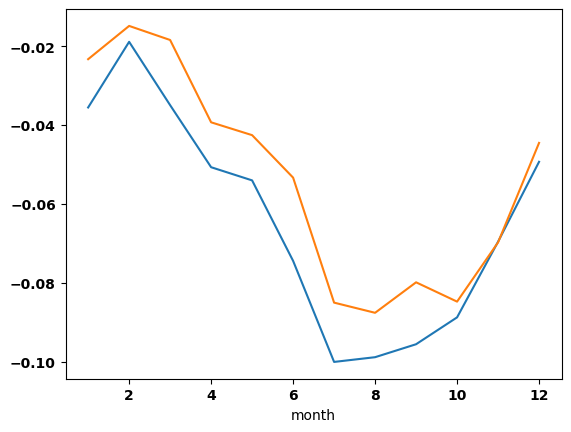

In [79]:
flux_SIO_1019.plot()
flux_SIO_8089.plot()

In [80]:
print(((flux_AS_1019.mean() - flux_AS_8089.mean())*100/flux_AS_8089.mean()),
((flux_BoB_1019.mean() - flux_BoB_8089.mean())*100/flux_BoB_8089.mean()),
((flux_EIO_1019.mean() - flux_EIO_8089.mean())*100/flux_EIO_8089.mean()),
((flux_SIO_1019.mean() - flux_SIO_8089.mean())*100/flux_SIO_8089.mean()))

<xarray.DataArray ()> Size: 8B
array(-42.57457635) <xarray.DataArray ()> Size: 8B
array(235.06294312) <xarray.DataArray ()> Size: 8B
array(248.10610593) <xarray.DataArray ()> Size: 8B
array(19.80631151)


In [81]:
import calendar
list(calendar.month_name)[1:]

['January',
 'February',
 'March',
 'April',
 'May',
 'June',
 'July',
 'August',
 'September',
 'October',
 'November',
 'December']

# Final figure

In [82]:
del_flux_anm_AS = sea_flux_AS_1019-sea_flux_AS_8089
del_flux_anm_BoB = sea_flux_BoB_1019-sea_flux_BoB_8089
del_flux_anm_EIO = sea_flux_EIO_1019-sea_flux_EIO_8089
del_flux_anm_SIO = sea_flux_SIO_1019-sea_flux_SIO_8089

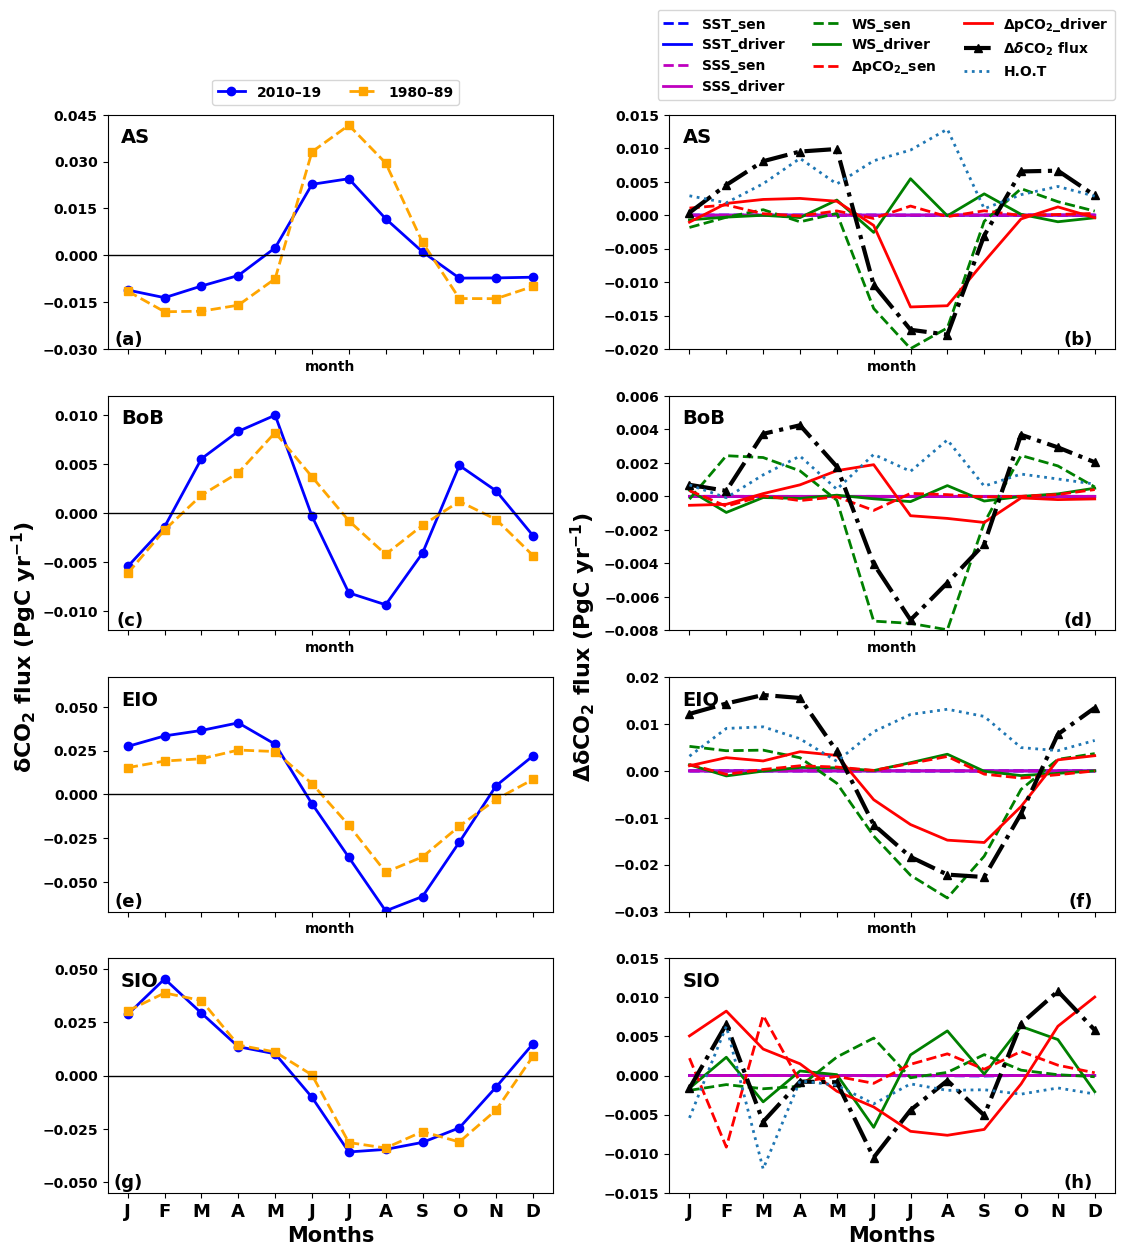

In [105]:
import matplotlib.pyplot as plt
import calendar

# ---------------------------
# Style
# ---------------------------
plt.rcParams["font.weight"] = "bold"
plt.rcParams["axes.labelweight"] = "bold"

regions = ["AS", "BoB", "EIO", "SIO"]
panel_labels = ['(a)', '(b)', '(c)', '(d)', '(e)', '(f)', '(g)', '(h)']

# ---------------------------
# Limits & ticks
# ---------------------------
ylim_driver = {
    "AS":  (-0.02, 0.015),
    "BoB": (-0.008, 0.006),
    "EIO": (-0.03, 0.02),
    "SIO": (-0.015, 0.015),
}

ylim_flux = {
    "AS":  (-0.03, 0.045),
    "BoB": (-0.012, 0.012),
    "EIO": (-0.067, 0.067),
    "SIO": (-0.055, 0.055),
}

yticks_flux = {
    "AS":  [-0.03, -0.015, 0, .015, 0.03, 0.045],
    "BoB": [-0.01, -0.005, 0, 0.005, 0.01],
    "EIO": [-0.05, -0.025, 0, 0.025, 0.05],
    "SIO": [-0.05, -0.025, 0, 0.025, 0.05],
}

# ---------------------------
# Figure (4 × 2)
# ---------------------------
fig, axes = plt.subplots(
    nrows=4, ncols=2,
    figsize=(13, 14),
    sharex=True
)

months = range(1, 13)
month_labels = ["J", "F", "M", "A", "M", "J", "J", "A", "S", "O", "N", "D"]#list(calendar.month_abbr)[1:]

pidx = 0  # panel label index

# ---------------------------
# Plot loop (row-wise by region)
# ---------------------------
for i, reg in enumerate(regions):

    ax_flux   = axes[i, 0]  # LEFT: flux anomalies
    ax_driver = axes[i, 1]  # RIGHT: drivers + sensitivities

    # ===== LEFT COLUMN: Flux anomalies =====
    globals()[f"sea_flux_{reg}_1019"].plot(
        ax=ax_flux, lw=2, c='b', marker='o',
        label='2010–19'
    )
    globals()[f"sea_flux_{reg}_8089"].plot(
        ax=ax_flux, lw=2, ls='--', c='orange', marker='s',
        label='1980–89'
    )
    ax_flux.axhline(y=0,c='k', lw=1)
    ax_flux.set_ylim(ylim_flux[reg])
    ax_flux.set_yticks(yticks_flux[reg])

    ax_flux.text(0.03, 0.88, reg,
                 transform=ax_flux.transAxes,
                 fontsize=14, fontweight='bold')

    ax_flux.text(0.08, 0.08, panel_labels[pidx],
                 transform=ax_flux.transAxes,
                 ha='right', va='top',
                 fontsize=13, fontweight='bold')
    pidx += 1

    # ===== RIGHT COLUMN: Drivers & sensitivities =====
    globals()[f"T_sen_{reg}"].plot(ax=ax_driver, ls='--', lw=2, c='b', label='SST_sen')
    globals()[f"T_driver_{reg}"].plot(ax=ax_driver, ls='-',  lw=2, c='b', label='SST_driver')

    globals()[f"S_sen_{reg}"].plot(ax=ax_driver, ls='--', lw=2, c='m', label='SSS_sen')
    globals()[f"S_driver_{reg}"].plot(ax=ax_driver, ls='-',  lw=2, c='m', label='SSS_driver')

    globals()[f"W_sen_{reg}"].plot(ax=ax_driver, ls='--', lw=2, c='g', label='WS_sen')
    globals()[f"W_driver_{reg}"].plot(ax=ax_driver, ls='-',  lw=2, c='g', label='WS_driver')

    globals()[f"P_sen_{reg}"].plot(
        ax=ax_driver, ls='--', lw=2, c='r',
        label=r'$\Delta$pCO$_2$_sen'
    )
    globals()[f"P_driver_{reg}"].plot(
        ax=ax_driver, ls='-', lw=2, c='r',
        label=r'$\Delta$pCO$_2$_driver'
    )
    globals()[f"del_flux_anm_{reg}"].plot(ax=ax_driver,ls='-.',marker='^',lw=3,c='k',label=r'$\Delta$$\delta$CO$_2$ flux')
    globals()[f"res_{reg}"].plot(ax=ax_driver, ls=':',  lw=2, label='H.O.T')

    ax_driver.text(0.03, 0.88, reg, transform=ax_driver.transAxes, fontsize=14, fontweight='bold')

    ax_driver.set_ylim(ylim_driver[reg])

    ax_driver.text(0.95, 0.08, panel_labels[pidx],
                   transform=ax_driver.transAxes,
                   ha='right', va='top',
                   fontsize=13, fontweight='bold')
    pidx += 1

# ---------------------------
# X ticks (only bottom row)
# ---------------------------
for ax in axes[-1, :]:
    ax.set_xticks(months)
    ax.set_xticklabels(month_labels, fontsize=13, fontweight='bold')
    ax.set_xlabel("Months",fontsize=15,fontweight="bold")

# # ---------------------------
# # Column titles
# # ---------------------------
# axes[0, 0].set_title(
#     r"$\mathbf{\delta}$CO$_2$ flux anomalies",
#     fontsize=15, fontweight='bold'
# )
# axes[0, 1].set_title(
#     r"Drivers & sensitivities of $\mathbf{\delta}$CO$_2$ flux",
#     fontsize=15, fontweight='bold'
# )

# ---------------------------
# Shared Y labels
# ---------------------------
fig.text(0.05, 0.5,
         r"$\mathbf{\delta}$CO$_2$ flux (PgC yr$^{-1}$)",
         va='center', rotation='vertical',
         fontsize=16, fontweight='bold')

fig.text(0.48, 0.5,
         r"$\mathbf{\Delta}$$\mathbf{\delta}$CO$_2$ flux (PgC yr$^{-1}$)",
         va='center', rotation='vertical',
         fontsize=16, fontweight='bold')

# ---------------------------
# Legends
# ---------------------------
handles_flux, labels_flux = axes[0, 0].get_legend_handles_labels()
handles_drv, labels_drv   = axes[0, 1].get_legend_handles_labels()

fig.legend(handles_flux, labels_flux,
           loc='upper left', bbox_to_anchor=(0.2, 0.91), ncols=2,
           frameon=True, fontsize=10)

fig.legend(handles_drv, labels_drv,
           loc='upper right', bbox_to_anchor=(0.905, 0.96),
           ncol=3, frameon=True, fontsize=10)
plt.subplots_adjust(wspace=0.26)
# plt.tight_layout(rect=[0.05, 0.05, 0.95, 0.94])
# plt.savefig('amplification_drivers_new_hot.png', dpi=500, bbox_inches='tight', facecolor='white')

plt.show()
